<a href="https://colab.research.google.com/github/prakshisagar/animal_inspection/blob/main/PerturbBench_FREE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PerturbBench — FREE-TIER RUN (one notebook, top to bottom)

**Zero paid services.** Everything runs on the free Colab T4 + free Hugging Face downloads. No Anthropic / OpenAI key needed.

**Before you press Run all**
1. `Runtime → Disconnect and delete runtime`, then `Runtime → Change runtime type → T4 GPU` (fresh runtime so the new `bitsandbytes` is picked up).
2. Run the **CONFIG** cell and set `QUICK_TEST = True` first (20 questions per exam, a few minutes) to check that every step works. Then set it to `False` and *Run all* again.
3. *(Optional)* a free Gemini key: https://aistudio.google.com/apikey → left sidebar 🔑 **Secrets** → add `GEMINI_API_KEY`, **Notebook access ON**, and set `RUN_GEMINI = True` in CONFIG. Skip it if you want zero setup — the notebook works fully without it.

**What changed vs. the Claude version**
| Before (needed paid key) | Now (free) |
|---|---|
| Data files had to already exist in Drive | Cell 5 **builds them automatically** from public HF datasets (no API, seed 42) if missing |
| Paraphrase v2 written by Claude Opus | Written by a **local open model** on the T4 (a model that is *not* evaluated → no self-preference). Which one was used is saved in `paraphraser_used.txt` |
| Claude Haiku / Sonnet evaluated on every row | Removed. Optional: **one Gemini free-tier model on a small subset** (`API_N_QUESTIONS`), resumable across days |

**Order of cells**
Install → CONFIG → Setup → Helpers → **Data build** → Extra twins → Paraphrase v2 → Evaluation engine → **RUN** (9 local models) → Analysis (~15 figures) → Digest + zip.

Everything is resumable: if Colab disconnects, reconnect, re-run Install / CONFIG / Setup / Helpers / Data build, then re-run the RUN cell — finished models and cached paraphrases are skipped. All outputs live in Drive (`WORKDIR`).


## 1 · Install

In [10]:
# --- install (bitsandbytes is needed for the 4-bit models) ---
!pip install -q -U "bitsandbytes>=0.46.1" accelerate scipy requests
import sys, importlib.metadata as md
print("bitsandbytes", md.version("bitsandbytes"), "| accelerate", md.version("accelerate"))
if "transformers" in sys.modules:
    print("\n[!] transformers was already imported in this session -> do Runtime > Restart session, then run from the top again.")


bitsandbytes 0.50.2 | accelerate 1.16.0


## 2 · CONFIG  (set `QUICK_TEST` here)

In [11]:
# ============================== CONFIG ==============================
QUICK_TEST = True          # True = 20 questions/exam, tiny run to verify the pipeline. Then set False.
WORKDIR = "/content/drive/MyDrive/PerturbBench"

RUN_LOCAL = True
REDO_PARAPHRASE = False     # True = regenerate paraphrase twins even if the file exists

# Optional free API reference model (Gemini free tier). Needs a free key in Colab Secrets: GEMINI_API_KEY.
# Free limits are small and change often, so it only runs on a SUBSET and resumes where it stopped (re-run tomorrow if the daily quota ends).
RUN_GEMINI = True
GEMINI_MODELS = None        # None = auto-pick one current Flash-Lite/Flash model from your key's model list. Or e.g. ["gemini-flash-lite-latest"]
API_N_QUESTIONS = 60        # questions used for the API model (each has ~10 twins -> ~600 requests)
GEMINI_RPM = 8              # requests per minute (stay under the free-tier limit; lower it if you see 429 errors)

# (hf_repo, size_in_B, family, load_in_4bit)  -- ordered by importance, so if time runs out the key ones are done
LOCAL_MODELS = [
    ("Qwen/Qwen2.5-0.5B-Instruct",          0.5,  "Qwen2.5",   False),
    ("Qwen/Qwen2.5-1.5B-Instruct",          1.5,  "Qwen2.5",   False),
    ("Qwen/Qwen2.5-3B-Instruct",            3.0,  "Qwen2.5",   False),
    ("Qwen/Qwen2.5-7B-Instruct",            7.0,  "Qwen2.5",   True),
    ("microsoft/Phi-3.5-mini-instruct",     3.8,  "Phi-3.5",   False),
    ("HuggingFaceTB/SmolLM2-1.7B-Instruct", 1.7,  "SmolLM2",   False),
    ("HuggingFaceTB/SmolLM2-360M-Instruct", 0.36, "SmolLM2",   False),
    ("Qwen/Qwen2.5-3B-Instruct",            3.0,  "Qwen2.5",   True),    # quantisation control (fp16 vs 4-bit)
    ("TinyLlama/TinyLlama-1.1B-Chat-v1.0",  1.1,  "TinyLlama", False),
]
# Local paraphraser (4-bit, tried in this order, first one that loads is used). None of them is in LOCAL_MODELS
# except the last-resort Qwen 14B (same family as the Qwen rows -> mention that caveat if it is the one used).
PARAPHRASER_CANDIDATES = [
    "mistralai/Mistral-7B-Instruct-v0.2",
    "NousResearch/Hermes-3-Llama-3.1-8B",
    "Qwen/Qwen2.5-14B-Instruct",
]
PARA_BS = 8             # paraphrase batch size
CALIB_TAG = "Qwen2.5-3B-Instruct"    # this model is also scored by generation+parsing (checks the logit-scoring method)

MAX_LEN = 3000          # tokens; truncation keeps the END of the prompt (the answer instruction)
TOK_BUDGET = 4096       # max (batch_size x longest_sequence) tokens per forward pass
MAX_BS = 16
PREFIX = "quick" if QUICK_TEST else "final"
PARA_FILE = f"{PREFIX}_paraphrase_v2_twins.jsonl"


## 3 · Setup  (Drive, optional key, GPU)

In [12]:
import os, torch
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(WORKDIR, exist_ok=True); os.chdir(WORKDIR)
print("working in:", os.getcwd())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "NONE -> Runtime > Change runtime type > T4 GPU")

GEMINI_KEY = None
if RUN_GEMINI:
    from google.colab import userdata
    try:
        GEMINI_KEY = userdata.get("GEMINI_API_KEY")
    except Exception:
        print("[!] GEMINI_API_KEY secret not found / notebook access off -> Gemini step skipped (everything else runs)")
RUN_GEMINI = bool(RUN_GEMINI and GEMINI_KEY)
print("Gemini reference model:", "ON" if RUN_GEMINI else "off (not needed)")
print("existing data files:", sorted(x for x in os.listdir(".") if x.endswith(".jsonl")))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
working in: /content/drive/MyDrive/PerturbBench
GPU: Tesla T4
Gemini reference model: ON
existing data files: ['benchmark_base.jsonl', 'paraphrase_twins.jsonl', 'perturbed_twins.jsonl', 'structural_twins.jsonl']


## 4 · Helpers

In [13]:
import re, json, time, random, threading
import numpy as np, pandas as pd
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

LETTERS = "ABCD"
INSTR = "\n\nAnswer with a single letter (A, B, C or D) only."
OPT_RE = re.compile(r"[\(\[]([A-D])[\)\]]")


def split_embedded(q):
    """JEE-Adv style '... (A) x (B) y (C) z (D) w' -> (stem, [4 options], bracket) or None"""
    ms = list(OPT_RE.finditer(q))
    if [m.group(1) for m in ms] != list(LETTERS):
        return None
    stem = q[:ms[0].start()].rstrip()
    opts = [q[ms[i].end(): ms[i + 1].start() if i < 3 else len(q)].strip() for i in range(4)]
    br = ("[", "]") if ms[0].group(0)[0] == "[" else ("(", ")")
    return stem, opts, br


def is_single_mcq(r):
    if not re.fullmatch(r"[A-D]", str(r["answer"])):
        return False
    return (r["exam"] == "NEET-PG" or
            (r["exam"] == "JEE-Main" and r["qtype"] == "single_correct") or
            (r["exam"] == "JEE-Adv" and r["qtype"] == "MCQ"))


def get_stem_opts(r):
    """-> (stem, [4 options], bracket) or None"""
    opts = r["options"]
    if isinstance(opts, list) and len(opts) == 4:
        return str(r["question"]).strip(), [str(o).strip() for o in opts], ("(", ")")
    return split_embedded(str(r["question"]))


def render(r):
    q = str(r["question"])
    opts = r["options"]
    if isinstance(opts, list) and len(opts) == 4:
        q += "\n\n" + "\n".join(f"{LETTERS[i]}. {opts[i]}" for i in range(4))
    return q + INSTR


# options whose meaning depends on position ("all of the above", "both A and B" ...) are never reordered
POSITIONAL = re.compile(
    r"(of the above|of these|both|neither|none of|all of"
    r"|(?:^|\s)\(?[a-d1-4]\)?\s*(?:and|&|or)\s*\(?[a-d1-4]\)?(?:\s|$)"
    r"|option\s*\(?[a-d1-4])", re.I)


def positional(opts):
    return any(POSITIONAL.search(str(o)) for o in opts)


# ------------------------- answer parsing -------------------------
_LETTER = re.compile(r"\b([ABCD])\b")


def parse_letter(text):
    m = _LETTER.search((text or "").upper())
    return m.group(1) if m else "X"            # X = unparseable -> counted wrong


## 5 · Data build  (free: public HF datasets, no API, seed 42)
Creates `benchmark_base.jsonl`, `perturbed_twins.jsonl`, `structural_twins.jsonl` in Drive **only if they are missing**, then loads the base questions.
Needs internet access to Hugging Face datasets (medmcqa, jeebench, eQOURSE/jee-main-questions) — free, no login.

In [14]:
# ============ data build (skipped automatically if the three files already exist) ============
import re, json, random
import pandas as pd

DATA_FILES = ["benchmark_base.jsonl", "perturbed_twins.jsonl", "structural_twins.jsonl"]

# ---------------- step 1: compile benchmark ----------------
SEED = 42
N_PER_EXAM = {"NEET-PG": 300, "JEE-Adv": 250, "JEE-Main": 250}
SCHEMA = ["id", "exam", "year", "subject", "qtype", "question", "options", "answer", "has_numbers", "source"]
SUBJECT_MAP = {"Math": "Mathematics", "Chem": "Chemistry", "Phy": "Physics"}
NUM_RE0 = re.compile(r"\d+(\.\d+)?")


def has_numbers(text):
    return len(NUM_RE0.findall(str(text))) >= 2


def stratified(df, n, by="subject"):
    if len(df) <= n:
        return df
    k = max(1, n // df[by].nunique())
    parts = [g.sample(min(len(g), k), random_state=SEED) for _, g in df.groupby(by)]
    return pd.concat(parts).sample(frac=1, random_state=SEED).head(n)


def to_letter(x):
    """normalize '1'/'1.0'/'A'/'a' -> 'A'... ; returns None if not a single option"""
    s = str(x).strip().upper()
    if s in ("A", "B", "C", "D"):
        return s
    try:
        i = int(float(s))
        if 1 <= i <= 4:
            return "ABCD"[i - 1]
    except ValueError:
        pass
    return None


def load_medmcqa():                       # NEET-PG
    from datasets import load_dataset
    df = load_dataset("openlifescienceai/medmcqa", split="validation").to_pandas()
    df = df[(df["choice_type"] == "single") & (df["cop"].between(0, 3))]
    df = df[df["question"].str.len() > 20]
    return pd.DataFrame({
        "id": "medmcqa_" + df["id"].astype(str),
        "exam": "NEET-PG", "year": None,
        "subject": df["subject_name"], "qtype": "MCQ_SINGLE",
        "question": df["question"].str.strip(),
        "options": df[["opa", "opb", "opc", "opd"]].values.tolist(),
        "answer": df["cop"].map(lambda i: "ABCD"[int(i)]),
        "source": "openlifescienceai/medmcqa",
    })


def load_jeebench():                      # JEE Advanced 2016-2023
    from datasets import load_dataset
    df = load_dataset("daman1209arora/jeebench", split="test").to_pandas()
    yr = df["description"].str.extract(r"(20\d\d)")[0].astype(float)
    return pd.DataFrame({
        "id": "jeebench_" + df.index.astype(str),      # NOT df["index"]: it repeats across subjects
        "exam": "JEE-Adv", "year": yr,
        "subject": df["subject"].str.capitalize(),
        "qtype": df["type"],
        "question": df["question"].str.strip(),
        "options": None,                       # options embedded in question text
        "answer": df["gold"].astype(str),
        "source": "daman1209arora/jeebench",
    })


def load_eqourse():                       # JEE Main (3 configs, noisy)
    from datasets import load_dataset
    frames = []
    for cfg in ["chemistry", "physics", "mathematics"]:
        dd = load_dataset("eQOURSE/jee-main-questions", cfg)
        d = dd[list(dd.keys())[0]].to_pandas()
        d["_subject"] = cfg.capitalize()
        frames.append(d)
    df = pd.concat(frames, ignore_index=True)
    q = df["question"].astype(str)
    bad = q.str.contains(r"\[IMAGE\]|¼|½", regex=True) | ~q.str.len().between(30, 1200)
    bad |= df["has_image"].astype(str).str.lower().isin(["true", "1"])
    df = df[~bad].copy()
    is_num = df["question_type"].astype(str).str.contains("numer", case=False)
    opts = df[["option_1", "option_2", "option_3", "option_4"]].astype(str).values.tolist()
    df["_opts"] = [None if n else o for n, o in zip(is_num, opts)]
    df["_ans"] = [str(na).strip() if n else to_letter(co)
                  for n, na, co in zip(is_num, df["numerical_answer"], df["correct_option"])]
    df = df[df["_ans"].notna() & ~df["_ans"].astype(str).str.lower().isin(["nan", "none", ""])]
    return pd.DataFrame({
        "id": "eq_" + df["question_id"].astype(str),
        "exam": "JEE-Main", "year": None, "subject": df["_subject"], "qtype": df["question_type"],
        "question": df["question"].astype(str).str.strip(),
        "options": df["_opts"], "answer": df["_ans"], "source": "eQOURSE/jee-main-questions",
    })


def build_benchmark():
    parts = []
    for name, fn in [("NEET-PG", load_medmcqa), ("JEE-Adv", load_jeebench), ("JEE-Main", load_eqourse)]:
        try:
            d = fn()
        except Exception as e:
            print(f"[skip] {name}: {e}"); continue
        if d is None or len(d) == 0:
            print(f"[skip] {name}: no rows"); continue
        d["subject"] = d["subject"].replace(SUBJECT_MAP)
        d = d[d["subject"].notna() & (d["subject"] != "Unknown")]
        d = d.drop_duplicates("question")
        d["has_numbers"] = d["question"].map(has_numbers)
        d = stratified(d, N_PER_EXAM[name])
        print(name, len(d), d["subject"].value_counts().to_dict())
        parts.append(d.dropna(axis=1, how="all"))
    assert parts, "no dataset could be loaded - check the internet / HF access"
    bench = pd.concat(parts, ignore_index=True).reindex(columns=SCHEMA)
    assert bench["id"].is_unique, "duplicate ids in benchmark"
    bench.to_json("benchmark_base.jsonl", orient="records", lines=True, force_ascii=False)
    print("saved benchmark_base.jsonl", len(bench))
    print(bench.groupby(["exam", "qtype"]).size())


# ---------------- step 2: option_shuffle / prefix_noise ----------------
PREFIXES = ["Read the question carefully and answer.",
            "Answer the following exam question.",
            "Consider the following problem from a competitive examination."]


def derangement(rng, n=4, tries=20):
    for _ in range(tries):
        p = list(range(n)); rng.shuffle(p)
        if p != list(range(n)):
            return p
    return list(range(n))[::-1]


def remap(ans, perm):
    """perm[new_idx] = old_idx ; gold letters -> new letters"""
    old_to_new = {old: new for new, old in enumerate(perm)}
    letters = re.findall(r"[A-D]", str(ans).upper())
    return "".join(sorted("ABCD"[old_to_new["ABCD".index(l)]] for l in letters))


def shuffle_row(r, rng):
    qtype, opts = str(r["qtype"]), r["options"]
    if isinstance(opts, list) and len(opts) == 4:                  # NEET-PG, JEE-Main MCQ
        if positional(opts) or not re.fullmatch(r"[A-D]", str(r["answer"])):
            return None
        perm = derangement(rng)
        return dict(question=r["question"], options=[opts[i] for i in perm], answer=remap(r["answer"], perm), perm=perm)
    if r["exam"] == "JEE-Adv" and qtype in ("MCQ", "MCQ(multiple)"):  # options embedded in text
        sp = split_embedded(r["question"])
        if sp is None:
            return None
        stem, o, br = sp
        if positional(o) or not re.search(r"[A-D]", str(r["answer"])):
            return None
        perm = derangement(rng)
        new = [o[i] for i in perm]
        q = stem + "\n\n" + "\n\n".join(f"{br[0]}{'ABCD'[i]}{br[1]} {new[i]}" for i in range(4))
        return dict(question=q, options=None, answer=remap(r["answer"], perm), perm=perm)
    return None


def build_perturbed(base, seed=42):
    rng, out = random.Random(seed), []
    for _, r in base.iterrows():
        meta = dict(orig_id=r["id"], exam=r["exam"], subject=r["subject"], qtype=r["qtype"])
        s = shuffle_row(r, rng)
        if s:
            out.append({**meta, "perturbation": "option_shuffle", **s})
        out.append({**meta, "perturbation": "prefix_noise", "question": rng.choice(PREFIXES) + "\n\n" + r["question"],
                    "options": r["options"], "answer": r["answer"], "perm": None})
    tw = pd.DataFrame(out)
    tw.to_json("perturbed_twins.jsonl", orient="records", lines=True, force_ascii=False)
    print("saved perturbed_twins.jsonl", len(tw))


# ---------------- step 5: structural twins (deterministic, no LLM) ----------------
SENT_SPLIT = re.compile(r"(?<=[.?!])\s+(?=[A-Z])")
QSTART = re.compile(r"^(find|what|which|calculate|determine|how|compute|evaluate|choose|identify)\b", re.I)
ANAPHORA = re.compile(r"\b(above|previous|this|these|those|such|it|its|they|their|then|thus|hence|same)\b", re.I)


def split_sentences(s):
    merged = []
    for p in SENT_SPLIT.split(s):             # re-join pieces if a $ is left open (LaTeX-safe)
        if merged and merged[-1].count("$") % 2 == 1:
            merged[-1] += " " + p
        else:
            merged.append(p)
    return merged


def question_first(stem):
    sents = split_sentences(stem)
    if len(sents) < 2:
        return None
    last = sents[-1].strip()
    if not (QSTART.match(last) or last.endswith("?")) or ANAPHORA.search(last):
        return None
    new = last + " " + " ".join(s.strip() for s in sents[:-1])
    return new if new != stem else None


lay_opts_first = lambda stem, o: "\n".join(f"{LETTERS[i]}. {o[i]}" for i in range(4)) + "\n\n" + stem
lay_opts_inline = lambda stem, o: stem + "\n\n" + "   ".join(f"{LETTERS[i]}) {o[i]}" for i in range(4))
lay_template = lambda stem, o: "Question: " + stem + "\n\nOptions:\n" + "\n".join(f"({LETTERS[i]}) {o[i]}" for i in range(4))
lay_plain = lambda stem, o: stem + "\n\n" + "\n".join(f"{LETTERS[i]}. {o[i]}" for i in range(4))


def build_structural(base):
    base = base[base.apply(is_single_mcq, axis=1)]
    rows = []
    for _, r in base.iterrows():
        g = get_stem_opts(r)
        if g is None:
            continue
        stem, o, _br = g
        meta = dict(orig_id=r["id"], exam=r["exam"], subject=r["subject"], qtype=r["qtype"],
                    options=None, answer=r["answer"], perm=None)
        variants = {"opts_first": lay_opts_first(stem, o), "opts_inline": lay_opts_inline(stem, o),
                    "template_wrap": lay_template(stem, o)}
        qf = question_first(stem)
        if qf:
            variants["q_first"] = lay_plain(qf, o)
        for name, q in variants.items():
            rows.append({**meta, "perturbation": name, "question": q})
    tw = pd.DataFrame(rows)
    tw.to_json("structural_twins.jsonl", orient="records", lines=True, force_ascii=False)
    print("saved structural_twins.jsonl", len(tw))
    print(tw.groupby(["exam", "perturbation"]).size().unstack(fill_value=0))
    qf = tw[tw.perturbation == "q_first"]
    if len(qf):
        qf.sample(min(30, len(qf)), random_state=42)[["orig_id", "question"]].to_csv("structural_audit.csv", index=False)


# ---------------- run whatever is missing ----------------
if not os.path.exists("benchmark_base.jsonl"):
    print("building benchmark_base.jsonl from Hugging Face datasets ...")
    build_benchmark()
_b = pd.read_json("benchmark_base.jsonl", lines=True)
if not os.path.exists("perturbed_twins.jsonl"):
    build_perturbed(_b)
if not os.path.exists("structural_twins.jsonl"):
    build_structural(_b)
for f in DATA_FILES:
    assert os.path.exists(f), f"{f} could not be created"

# ---------------- load base ----------------
base_all = pd.read_json("benchmark_base.jsonl", lines=True)
assert base_all["id"].is_unique
base = base_all[base_all.apply(is_single_mcq, axis=1)].copy()
if QUICK_TEST:
    base = base.groupby("exam").head(20).copy()
print("data files OK:", sorted(x for x in os.listdir(".") if x.endswith(".jsonl")))
print("single-answer MCQs used:", len(base), base.groupby("exam").size().to_dict())


data files OK: ['benchmark_base.jsonl', 'paraphrase_twins.jsonl', 'perturbed_twins.jsonl', 'structural_twins.jsonl']
single-answer MCQs used: 60 {'JEE-Adv': 20, 'JEE-Main': 20, 'NEET-PG': 20}


## 6 · Extra twins  (`opts_first_labeled`, `option_rotate_balanced`)

In [15]:
# Two extra twins, both gold-preserving and deterministic (seed 42):
#  opts_first_labeled     : "Options: ... / Question: ..."  -> separates 'options before stem' from 'no labels'
#  option_rotate_balanced : each gold answer is moved to a letter chosen so the NEW gold letters are ~uniform A-D
POSITIONAL = re.compile(
    r"(of the above|of these|both|neither|none of|all of"
    r"|(?:^|\s)\(?[a-d1-4]\)?\s*(?:and|&|or)\s*\(?[a-d1-4]\)?(?:\s|$)"
    r"|option\s*\(?[a-d1-4])", re.I)


def positional(opts):
    return any(POSITIONAL.search(str(o)) for o in opts)


def build_extra(base, seed=42):
    rng = random.Random(seed)
    rows, counts = [], Counter()
    order = list(base.index); rng.shuffle(order)
    for idx in order:
        r = base.loc[idx]
        g = get_stem_opts(r)
        if g is None:
            continue
        stem, o, br = g
        meta = dict(orig_id=r["id"], exam=r["exam"], subject=r["subject"], qtype=r["qtype"])
        q_lab = "Options:\n" + "\n".join(f"{LETTERS[i]}. {o[i]}" for i in range(4)) + "\n\nQuestion: " + stem
        rows.append({**meta, "perturbation": "opts_first_labeled", "question": q_lab,
                     "options": None, "answer": r["answer"], "perm": None})
        if positional(o):
            continue
        gi = LETTERS.index(r["answer"])
        t = min([x for x in range(4) if x != gi], key=lambda x: (counts[x], rng.random()))
        counts[t] += 1
        perm = [(k - t + gi) % 4 for k in range(4)]          # perm[new_pos] = old_pos ; old gold lands on t
        new = [o[i] for i in perm]
        if isinstance(r["options"], list) and len(r["options"]) == 4:
            q, opts = str(r["question"]), new
        else:
            q = stem + "\n\n" + "\n\n".join(f"{br[0]}{LETTERS[i]}{br[1]} {new[i]}" for i in range(4)); opts = None
        rows.append({**meta, "perturbation": "option_rotate_balanced", "question": q,
                     "options": opts, "answer": LETTERS[t], "perm": perm})
    return pd.DataFrame(rows)


extra = build_extra(base_all[base_all.apply(is_single_mcq, axis=1)])      # always built on the full base
extra.to_json("extra_twins.jsonl", orient="records", lines=True, force_ascii=False)
print("saved extra_twins.jsonl", len(extra))
print(extra.groupby(["exam", "perturbation"]).size().unstack(fill_value=0))
print("gold letters after balanced rotation:",
      extra[extra.perturbation == "option_rotate_balanced"].answer.value_counts(normalize=True).round(2).to_dict())


saved extra_twins.jsonl 1020
perturbation  option_rotate_balanced  opts_first_labeled
exam                                                    
JEE-Adv                           42                  42
JEE-Main                         165                 189
NEET-PG                          291                 291
gold letters after balanced rotation: {'D': 0.25, 'A': 0.25, 'C': 0.25, 'B': 0.25}


## 6b · Paraphrase v2  (local open model on the T4, free; skipped if the file exists)

In [16]:
# Paraphrase v2: a LOCAL open model rewrites the stem only (options untouched -> gold stays valid).
# Automatic filters (numbers, LaTeX, key terms, length, not-a-copy) do NOT prove meaning is preserved
# -> audit paraphrase_v2_audit_*.csv by hand (fill the empty column) and report the % that were fine.
from collections import Counter
PROMPT = ("Rewrite the following exam question so that the wording and sentence structure are different, "
          "but the meaning is exactly the same. Keep every number, unit, symbol, formula (including anything "
          "between $ signs) and technical term unchanged. Do not answer the question, do not add or remove "
          "information. Output only the rewritten question.\n\nQuestion:\n{stem}")
NUM = re.compile(r"\d+(?:\.\d+)?")
LATEX = re.compile(r"\$[^$]+\$")
WORD = re.compile(r"[A-Za-z]{7,}")
GENERIC = {"following", "statement", "statements", "correct", "incorrect", "regarding", "consider",
           "question", "respectively", "between", "possible", "options", "choose", "determine",
           "calculate", "assuming", "according", "denotes", "present", "obtained"}


def validate(orig, new):
    if not new or new.strip() == orig.strip():
        return "identical"
    if re.match(r"(?i)\s*(here is|here's|rewritten|sure|paraphras|question:)", new):
        return "meta"
    if Counter(NUM.findall(orig)) != Counter(NUM.findall(new)):
        return "numbers"
    if any(m not in new for m in LATEX.findall(orig)):
        return "latex"
    if not 0.5 <= len(new) / max(1, len(orig)) <= 1.8:
        return "length"
    ow = {w.lower() for w in WORD.findall(orig)} - GENERIC
    nw = {w.lower() for w in WORD.findall(new)}
    if ow and len(ow & nw) / len(ow) < 0.6:                 # was 0.7 (rejected 156 NEET-PG rows)
        return "terms"
    a, b = set(orig.lower().split()), set(new.lower().split())
    if len(a & b) / max(1, len(a | b)) > 0.9:
        return "too_similar"
    return "ok"


def get_stem_rebuild(r):
    g = get_stem_opts(r)
    if g is None:
        return None
    stem, o, br = g
    if isinstance(r["options"], list) and len(r["options"]) == 4:
        return str(r["question"]), (lambda s: s)
    return stem, (lambda s: s + "\n\n" + "\n\n".join(f"{br[0]}{LETTERS[i]}{br[1]} {o[i]}" for i in range(4)))


def clean_para(t):
    t = (t or "").strip()
    t = re.sub(r"(?is)^\s*(rewritten question|rewritten version|paraphrased question|paraphrase|question)\s*:\s*", "", t).strip()
    if len(t) > 2 and t[0] == t[-1] and t[0] in "\"'":
        t = t[1:-1].strip()
    return t


def purge_hf_cache(repo):
    """free Colab disk after the paraphraser is done (the evaluated models are kept)"""
    try:
        from huggingface_hub import scan_cache_dir
        c = scan_cache_dir()
        revs = [rv.commit_hash for r in c.repos if r.repo_id == repo for rv in r.revisions]
        if revs:
            c.delete_revisions(*revs).execute()
    except Exception as e:
        print("[cache purge skipped]", str(e)[:100])


def local_paraphrase(stems):
    """stems: {id: stem}. Returns ({id: paraphrase}, model_name). Greedy decoding, 4-bit, batched."""
    import gc, torch
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    name = tok = model = None
    for cand in PARAPHRASER_CANDIDATES:
        try:
            tok = AutoTokenizer.from_pretrained(cand)
            model = AutoModelForCausalLM.from_pretrained(
                cand, device_map="auto",
                quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                       bnb_4bit_compute_dtype=torch.float16)).eval()
            name = cand; break
        except Exception as e:
            print(f"[paraphraser] could not load {cand}: {str(e)[:150]}")
            model = None; gc.collect(); torch.cuda.empty_cache()
    if model is None:
        return {}, None
    print("paraphraser:", name)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    ids = list(stems)
    texts = {i: tok.apply_chat_template([{"role": "user", "content": PROMPT.format(stem=stems[i])}],
                                        tokenize=False, add_generation_prompt=True) for i in ids}
    lens = {i: len(tok(texts[i], add_special_tokens=False).input_ids) for i in ids}
    ids.sort(key=lambda i: lens[i])
    out = {}
    for s in range(0, len(ids), PARA_BS):
        b = ids[s:s + PARA_BS]
        enc = tok([texts[i] for i in b], return_tensors="pt", padding=True, add_special_tokens=False,
                  truncation=True, max_length=2500).to(model.device)
        with torch.no_grad():
            g = model.generate(**enc, max_new_tokens=min(700, int(lens[b[-1]] * 1.2) + 60), do_sample=False,
                               pad_token_id=tok.pad_token_id)
        for i, t in zip(b, tok.batch_decode(g[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)):
            out[i] = clean_para(t)
        print(f"  {min(s + PARA_BS, len(ids))}/{len(ids)}", end="\r")
    del model; gc.collect(); torch.cuda.empty_cache()
    return out, name


def paraphrase_v2():
    if os.path.exists(PARA_FILE) and not REDO_PARAPHRASE:
        print(f"{PARA_FILE} exists -> reusing (set REDO_PARAPHRASE=True to regenerate)"); return
    b = base_all[base_all.apply(is_single_mcq, axis=1)]
    cand = []
    for _, r in b.iterrows():
        g = get_stem_rebuild(r)
        if g and len(g[0]) >= 40:
            cand.append((r, g[0], g[1]))
    if QUICK_TEST:
        cand = cand[:12]
    cache_f = f"cache_{PREFIX}_paraphrase_v2.json"
    cache = json.load(open(cache_f)) if os.path.exists(cache_f) else {}
    todo = {r["id"]: stem for r, stem, _ in cand if r["id"] not in cache}
    print(f"paraphrasing {len(todo)} stems with a local model (~10-25 min on T4 for the full set)")
    used = None
    if todo:
        res, used = local_paraphrase(todo)
        cache.update(res)
        json.dump(cache, open(cache_f, "w"))
        if used:
            open("paraphraser_used.txt", "w").write(used + "\n")
            purge_hf_cache(used)
        else:
            print("[skip] no paraphraser model could be loaded -> the 'paraphrase' perturbation will be missing"); return
    rows, audit, stats = [], [], []
    for r, stem, rebuild in cand:
        pp = cache.get(r["id"], "")
        why = validate(stem, pp)
        stats.append((r["exam"], why))
        if why == "ok":
            rows.append(dict(orig_id=r["id"], exam=r["exam"], subject=r["subject"], qtype=r["qtype"],
                             perturbation="paraphrase", question=rebuild(pp), options=r["options"],
                             answer=r["answer"], perm=None))
            audit.append(dict(orig_id=r["id"], exam=r["exam"], original=stem, paraphrase=pp))
    tw, au = pd.DataFrame(rows), pd.DataFrame(audit)
    if len(tw) == 0:
        print("[warn] no paraphrase passed the filters"); return
    tw.to_json(PARA_FILE, orient="records", lines=True, force_ascii=False)
    au.sample(min(40, len(au)), random_state=42).assign(meaning_preserved_YN="").to_csv(
        f"paraphrase_v2_audit_{PREFIX}.csv", index=False)
    st = pd.DataFrame(stats, columns=["exam", "result"])
    print(f"\nkept {len(tw)} of {len(st)}"); print(st.groupby(["exam", "result"]).size().unstack(fill_value=0))
    print(f"-> open paraphrase_v2_audit_{PREFIX}.csv and mark Y/N for the pairs (needed to report paraphrase validity)")


paraphrase_v2()


paraphrasing 12 stems with a local model (~10-25 min on T4 for the full set)


config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  493kB            

tokenizer.model: downloading bytes:           |  0.00B            

... (3 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

paraphraser: mistralai/Mistral-7B-Instruct-v0.2

kept 5 of 12
result   length  numbers  ok  terms
exam                               
NEET-PG       2        2   5      3
-> open paraphrase_v2_audit_quick.csv and mark Y/N for the pairs (needed to report paraphrase validity)


## 7 · Evaluation engine  (just defines functions)

In [17]:
# ======================= evaluation engine =======================
def load_eval_rows():
    b = base.copy()
    b["orig_id"] = b["id"]; b["perturbation"] = "original"; b["perm"] = None
    para = PARA_FILE
    print("paraphrase file used:", para if os.path.exists(para) else "NONE (paraphrase perturbation skipped)")
    files = ["perturbed_twins.jsonl", "structural_twins.jsonl", "extra_twins.jsonl", para]
    tw = pd.concat([pd.read_json(f, lines=True) for f in files if os.path.exists(f)], ignore_index=True)
    tw = tw[tw["orig_id"].isin(b["id"])]
    cols = ["orig_id", "exam", "subject", "qtype", "perturbation", "question", "options", "answer", "perm"]
    rows = pd.concat([b[cols], tw[cols]], ignore_index=True)
    assert not rows.duplicated(["orig_id", "perturbation"]).any(), "duplicate (question, perturbation) rows"
    return rows


def finish(rows, preds, tag, size, fam, kind, quant):
    out = rows.copy()
    out["pred"] = preds
    # prediction expressed in ORIGINAL option order so shuffled/rotated twins are comparable
    out["pred_orig_space"] = [
        LETTERS[int(p[LETTERS.index(pr)])] if (isinstance(p, list) and pr in LETTERS) else pr
        for pr, p in zip(preds, out["perm"])]
    out["correct"] = out["pred"] == out["answer"]
    out["model"], out["size_b"], out["family"], out["kind"], out["quant"] = tag, size, fam, kind, quant
    return out


def plan_batches(lens, tok_budget=TOK_BUDGET, max_bs=MAX_BS):
    """sort by length, pack so that batch_size * longest <= tok_budget"""
    order = sorted(range(len(lens)), key=lambda i: lens[i])
    batches, cur = [], []
    for i in order:
        if cur and (len(cur) + 1) * lens[i] > tok_budget or len(cur) >= max_bs:
            batches.append(cur); cur = []
        cur.append(i)
    if cur:
        batches.append(cur)
    return batches


# ------------------------------ local ------------------------------
def run_local(name, quant, rows, calib_idx=None):
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(name)
    tok.padding_side = "left"; tok.truncation_side = "left"      # keep the END of long prompts
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    kw = dict(device_map="auto")
    if quant:
        from transformers import BitsAndBytesConfig
        kw["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
    else:
        kw["torch_dtype"] = torch.float16
    model = AutoModelForCausalLM.from_pretrained(name, **kw).eval()
    ids = [[tok.encode(l, add_special_tokens=False)[0], tok.encode(" " + l, add_special_tokens=False)[-1]]
           for l in LETTERS]
    texts = [tok.apply_chat_template([{"role": "user", "content": render(r)}], tokenize=False,
                                     add_generation_prompt=True) for _, r in rows.iterrows()]
    lens = [min(len(tok(t, add_special_tokens=False).input_ids), MAX_LEN) for t in texts]

    def enc_of(idx):
        return tok([texts[i] for i in idx], return_tensors="pt", padding=True, truncation=True,
                   max_length=MAX_LEN, add_special_tokens=False).to(model.device)

    def score(idx):
        enc = enc_of(idx)
        with torch.no_grad():
            try:
                lg = model(**enc, use_cache=False, logits_to_keep=1).logits[:, -1].float()
            except TypeError:                                    # older transformers
                lg = model(**enc, use_cache=False).logits[:, -1].float()
        sc = torch.stack([torch.maximum(lg[:, a], lg[:, b]) for a, b in ids], 1)
        return sc.argmax(1).tolist()

    preds = [None] * len(texts)
    batches = plan_batches(lens)
    for n, b in enumerate(batches):
        try:
            res = score(b)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); res = [score([i])[0] for i in b]
        for i, p in zip(b, res):
            preds[i] = LETTERS[p]
        if n % 20 == 0:
            print(f"  batch {n}/{len(batches)}", end="\r")

    calib = None
    if calib_idx is not None:                                    # same model, but generation + parsing
        gen_preds = {}
        cl = [i for i in calib_idx]
        for b in plan_batches([lens[i] for i in cl], max_bs=8):
            idx = [cl[j] for j in b]
            enc = enc_of(idx)
            with torch.no_grad():
                g = model.generate(**enc, max_new_tokens=4, do_sample=False, pad_token_id=tok.pad_token_id)
            for i, t in zip(idx, tok.batch_decode(g[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)):
                gen_preds[i] = parse_letter(t)
        calib = gen_preds
    del model; torch.cuda.empty_cache()
    return preds, calib


# ------------------- optional: Gemini free tier (subset, resumable) -------------------
def gemini_pick_models():
    """one current Flash-Lite / Flash model that your key can call (names change often, so we ask the API)"""
    import requests
    r = requests.get("https://generativelanguage.googleapis.com/v1beta/models",
                     params={"key": GEMINI_KEY, "pageSize": 200}, timeout=30)
    r.raise_for_status()
    bad = ("image", "tts", "live", "audio", "embedding", "exp", "thinking", "robotics", "computer", "veo", "imagen", "gemma", "learnlm")
    names = [m["name"].split("/")[-1] for m in r.json().get("models", [])
             if "generateContent" in m.get("supportedGenerationMethods", [])]
    names = [n for n in names if n.startswith("gemini") and not any(x in n for x in bad)]
    for key in ("flash-lite", "flash"):
        c = sorted([n for n in names if key in n and "preview" not in n], reverse=True) or sorted([n for n in names if key in n], reverse=True)
        if c:
            return [c[0]]
    raise RuntimeError("no suitable Gemini model for this key: " + ", ".join(names[:10]))


def gemini_ask(prompt, model, state):
    """returns text, or None if the call could not be completed (quota / persistent error) -> NOT cached"""
    import requests
    url = f"https://generativelanguage.googleapis.com/v1beta/models/{model}:generateContent"
    for attempt in range(5):
        if state.get("stop"):
            return None
        think_off = state.get("nothink", True)
        cfg = {"temperature": 0, "maxOutputTokens": 16 if think_off else 1024}
        if think_off:
            cfg["thinkingConfig"] = {"thinkingBudget": 0}
        try:
            r = requests.post(url, params={"key": GEMINI_KEY}, timeout=60,
                              json={"contents": [{"parts": [{"text": prompt}]}], "generationConfig": cfg})
        except Exception:
            time.sleep(2 ** attempt); continue
        if r.status_code == 200:
            try:
                return "".join(p.get("text", "") for p in r.json()["candidates"][0]["content"].get("parts", []))
            except Exception:
                return ""                                   # blocked / empty answer -> counted as unparseable
        t = r.text.lower()
        if r.status_code == 429:
            if "perday" in t or "per day" in t or "daily" in t:
                state["stop"] = "daily free quota reached"; return None
            time.sleep(20 * (attempt + 1)); continue
        if r.status_code == 400 and "thinking" in t and think_off:
            state["nothink"] = False; continue               # this model does not allow thinkingBudget=0
        if r.status_code in (401, 403):
            state["stop"] = f"key rejected ({r.status_code})"; return None
        time.sleep(2 ** attempt)
    return None


def run_gemini(model, rws):
    cache_f = f"cache_{PREFIX}_{model}.json"
    cache = json.load(open(cache_f)) if os.path.exists(cache_f) else {}
    keyf = lambda r: f"{r.orig_id}|{r.perturbation}"
    state, fails = {}, 0
    for n, (_, r) in enumerate(rws.iterrows()):
        k = keyf(r)
        if k in cache:
            continue
        t = gemini_ask(render(r), model, state)
        if t is None:
            fails += 1
            if state.get("stop") or fails >= 5:
                break
            continue
        fails = 0
        cache[k] = parse_letter(t)
        if n % 25 == 0:
            json.dump(cache, open(cache_f, "w"))
        time.sleep(60.0 / GEMINI_RPM)
    json.dump(cache, open(cache_f, "w"))
    missing = sum(keyf(r) not in cache for _, r in rws.iterrows())
    if missing:
        return None, f"PARTIAL: {len(rws) - missing}/{len(rws)} done ({state.get('stop', 'errors')}) -> re-run this cell later, it resumes"
    return [cache[keyf(r)] for _, r in rws.iterrows()], "done"


## 8 · RUN EVERYTHING  (local models on the T4; optional Gemini subset in the background; resumable)

In [18]:
# ============================ RUN EVERYTHING ============================
rows = load_eval_rows()
print(rows.groupby(["exam", "perturbation"]).size().unstack(fill_value=0).to_string())
print("total rows per model:", len(rows))
orig_idx = list(np.where(rows.perturbation.values == "original")[0])
api_log = {}


def api_job():
    try:
        models = GEMINI_MODELS or gemini_pick_models()
    except Exception as e:
        api_log["gemini"] = f"FAILED: {e}"; return
    orig = rows[rows.perturbation == "original"]
    keep = set()
    for ex in ["NEET-PG", "JEE-Main"]:                       # only the exams used in the main claims, equal share
        ids = sorted(orig[orig.exam == ex].orig_id.unique()); random.Random(0).shuffle(ids)
        keep |= set(ids[:max(1, API_N_QUESTIONS // 2)])
    sub = rows[rows.orig_id.isin(keep)].reset_index(drop=True)
    print(f"[gemini] {models} on {len(keep)} questions / {len(sub)} rows")
    for model in models:
        f = f"{PREFIX}_{model}.csv"
        if os.path.exists(f):
            api_log[model] = "skipped (exists)"; continue
        try:
            preds, msg = run_gemini(model, sub)
            if preds is not None:
                out = finish(sub, preds, model, float("nan"), "Gemini", "api", False)
                out.to_csv(f, index=False)
                o = out[out.perturbation == "original"]
                msg = f"done | orig acc {o.correct.mean():.3f} | unparseable {np.mean(out.pred == 'X'):.4f}"
            api_log[model] = msg
        except Exception as e:
            api_log[model] = f"FAILED: {e}"


api_thread = None
if RUN_GEMINI:
    api_thread = threading.Thread(target=api_job, daemon=True); api_thread.start()
    print("Gemini subset started in the background")

if RUN_LOCAL:
    for name, size, fam, quant in LOCAL_MODELS:
        tag = name.split("/")[-1] + ("@4bit" if quant else "")
        f = f"{PREFIX}_{tag}.csv"
        if os.path.exists(f):
            print("[skip, exists]", tag); continue
        t0 = time.time(); print("\n==", tag)
        try:
            preds, calib = run_local(name, quant, rows, calib_idx=orig_idx if tag == CALIB_TAG else None)
        except Exception as e:
            print(f"[fail] {tag}: {e}"); continue
        out = finish(rows, preds, tag, size, fam, "local", quant)
        out.to_csv(f, index=False)
        o = out[out.perturbation == "original"]
        print(f"original acc {o.correct.mean():.3f} | {(time.time() - t0) / 60:.1f} min")
        if calib is not None:
            gp = [calib[i] for i in orig_idx]
            gold = o.answer.tolist()
            res = dict(model=tag, acc_logits=float(o.correct.mean()),
                       acc_generation=float(np.mean([g == a for g, a in zip(gp, gold)])),
                       agreement=float(np.mean([g == p for g, p in zip(gp, o.pred.tolist())])),
                       unparseable=float(np.mean([g == "X" for g in gp])))
            json.dump(res, open(f"{PREFIX}_calibration.json", "w"), indent=1)
            print("CALIBRATION (logit scoring vs generation+parsing):", res)

if api_thread is not None:
    print("\nwaiting for the Gemini subset ... (Ctrl-C / interrupt is safe, it resumes next time)")
    api_thread.join()
for k, v in api_log.items():
    print("API", k, "->", v)
print("\nfiles:", sorted(x for x in os.listdir('.') if x.startswith(PREFIX + "_")))


paraphrase file used: quick_paraphrase_v2_twins.jsonl
perturbation  option_rotate_balanced  option_shuffle  opts_first  opts_first_labeled  opts_inline  original  paraphrase  prefix_noise  q_first  template_wrap
exam                                                                                                                                                         
JEE-Adv                           20              20          20                  20           20        20           0            20        2             20
JEE-Main                          16              16          20                  20           20        20           0            20        1             20
NEET-PG                           20              20          20                  20           20        20           5            20        4             20
total rows per model: 484
Gemini subset started in the background

== Qwen2.5-0.5B-Instruct


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

[gemini] ['gemini-flash-lite-latest'] on 40 questions / 322 rows


vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (82 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

original acc 0.283 | 0.7 min

waiting for the Gemini subset ... (Ctrl-C / interrupt is safe, it resumes next time)
API gemini-flash-lite-latest -> PARTIAL: 0/322 done (errors) -> re-run this cell later, it resumes

files: ['quick_Phi-3.5-mini-instruct.csv', 'quick_Qwen2.5-0.5B-Instruct.csv', 'quick_Qwen2.5-1.5B-Instruct.csv', 'quick_Qwen2.5-3B-Instruct.csv', 'quick_Qwen2.5-3B-Instruct@4bit.csv', 'quick_Qwen2.5-7B-Instruct@4bit.csv', 'quick_SmolLM2-1.7B-Instruct.csv', 'quick_SmolLM2-360M-Instruct.csv', 'quick_TinyLlama-1.1B-Chat-v1.0.csv', 'quick_calibration.json', 'quick_paraphrase_v2_twins.jsonl']


## 9 · Analysis + figures  (shown inline, saved to `figs_final/`)

models: ['Phi-3.5-mini', 'Qwen-0.5B', 'Qwen-1.5B', 'Qwen-3B', 'Qwen-3B (4b)', 'Qwen-7B (4b)', 'SmolLM2-1.7B', 'SmolLM2-360M', 'TinyLlama-1.1B']


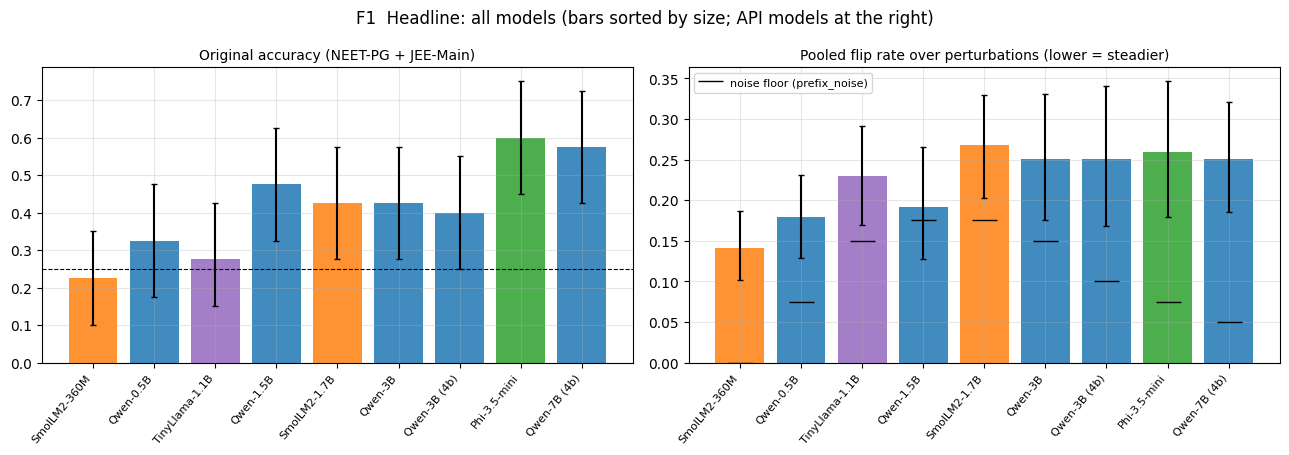

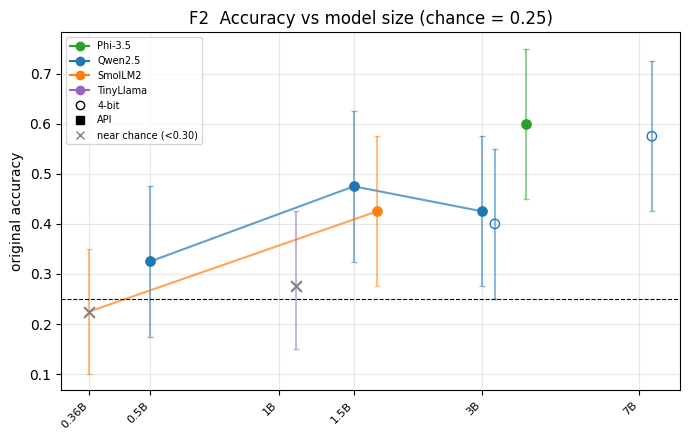

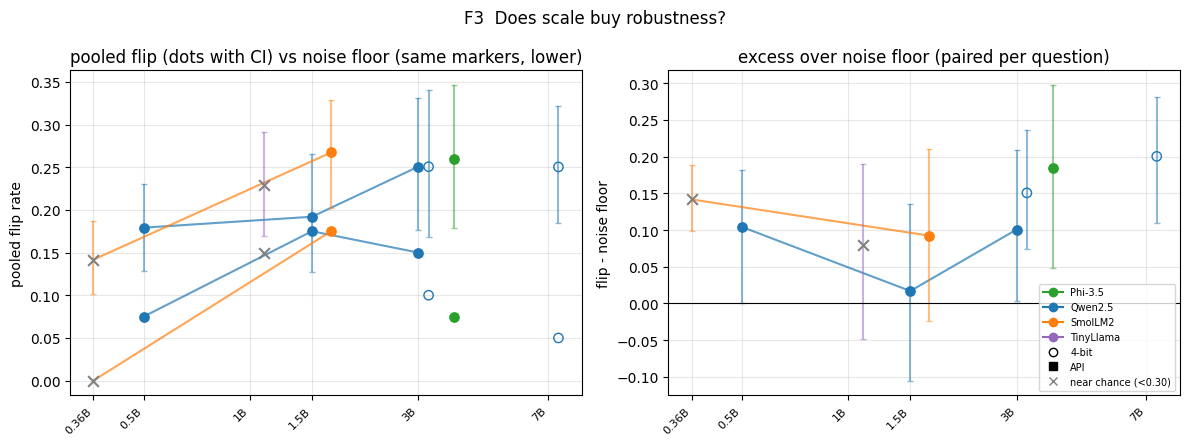

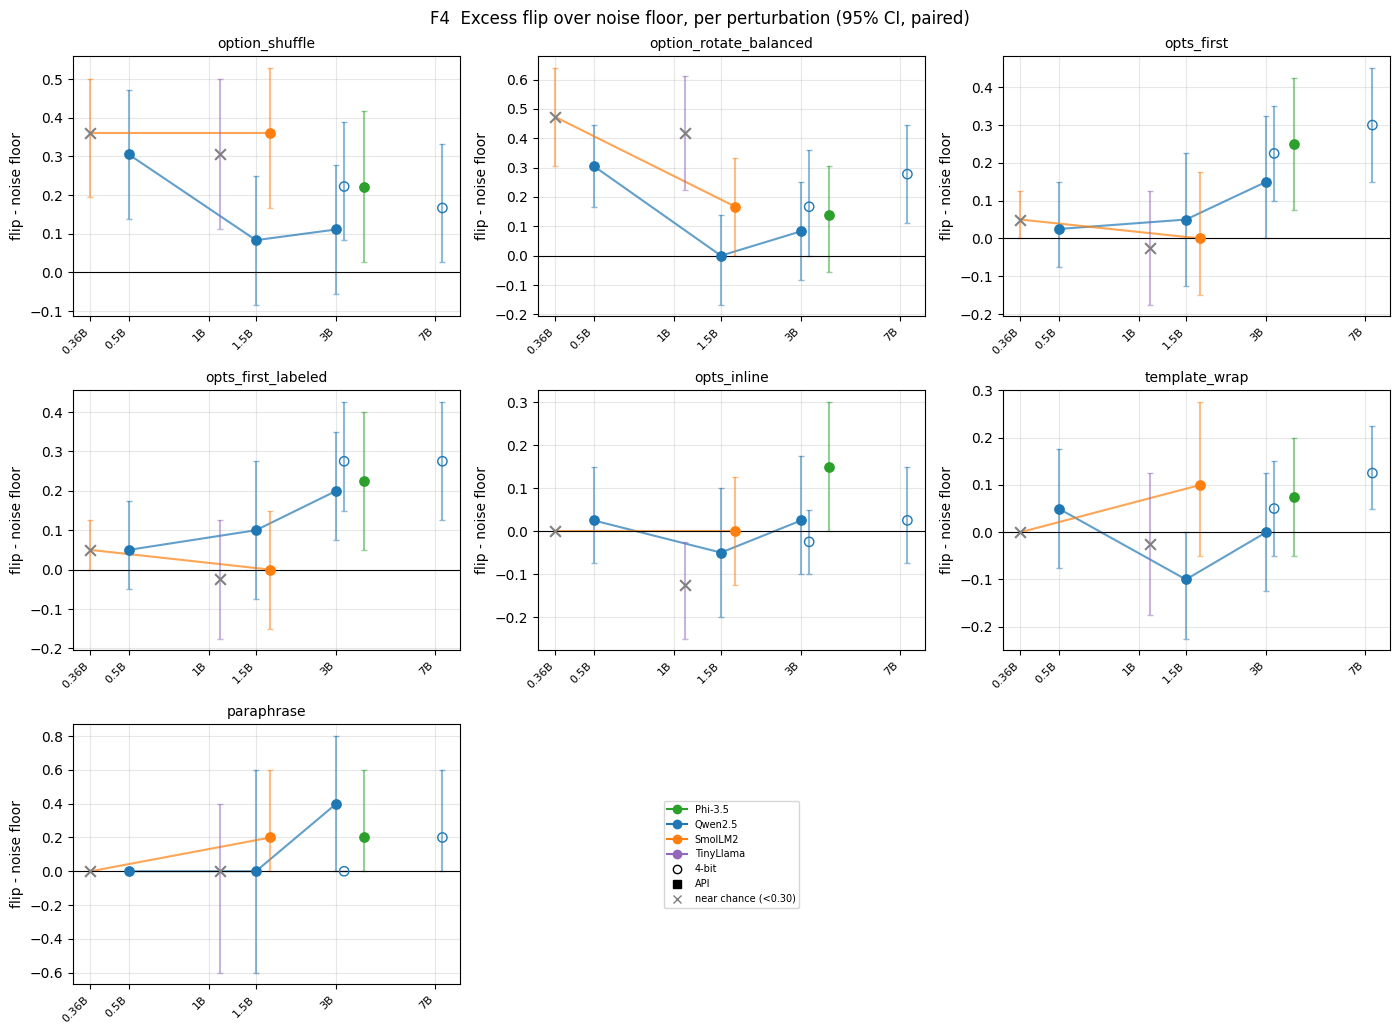

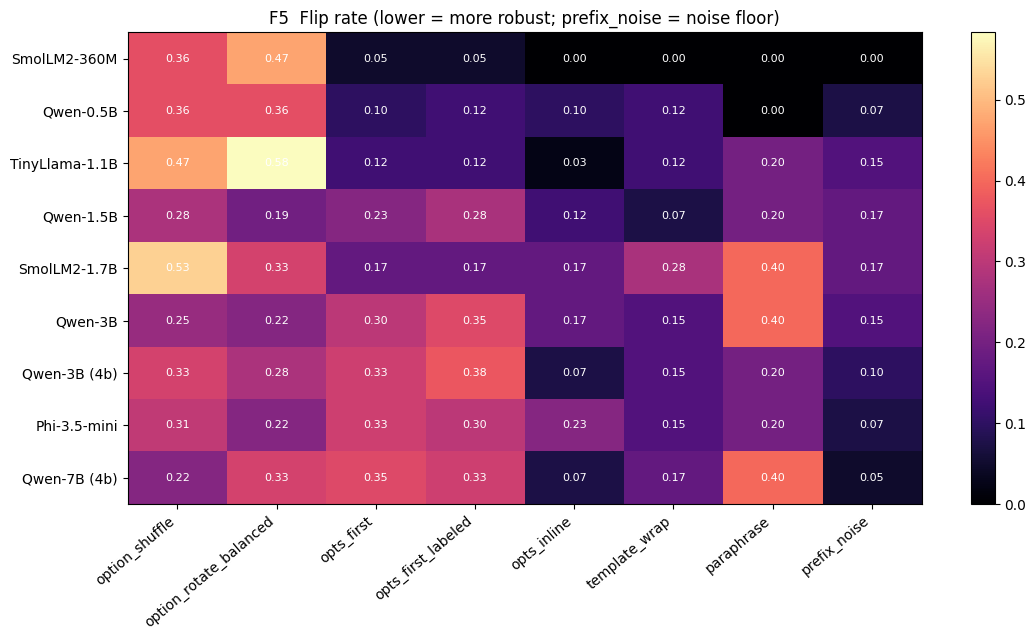

/tmp/ipykernel_773/1378367658.py:239: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Hs = S[S.perturbation != NOISE].pivot(index="model", columns="perturbation", values="sig").reindex(order)[twin_perts].fillna(False).astype(bool)


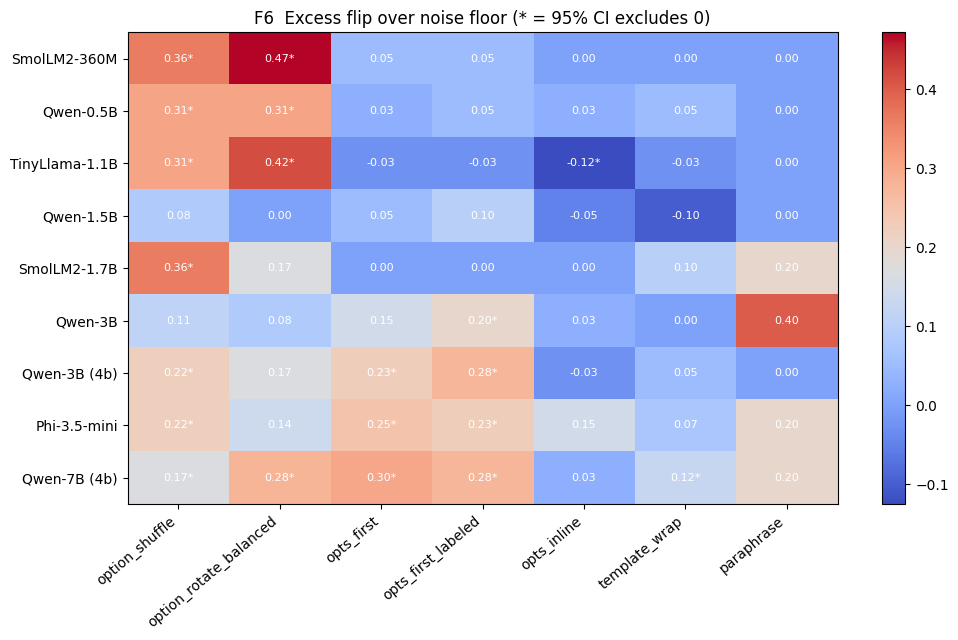

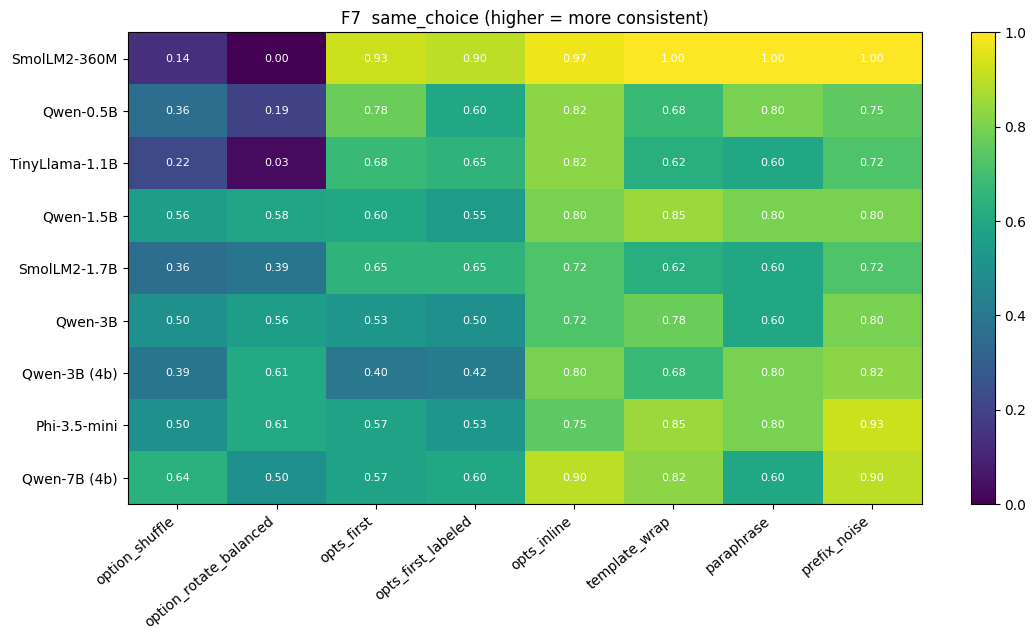

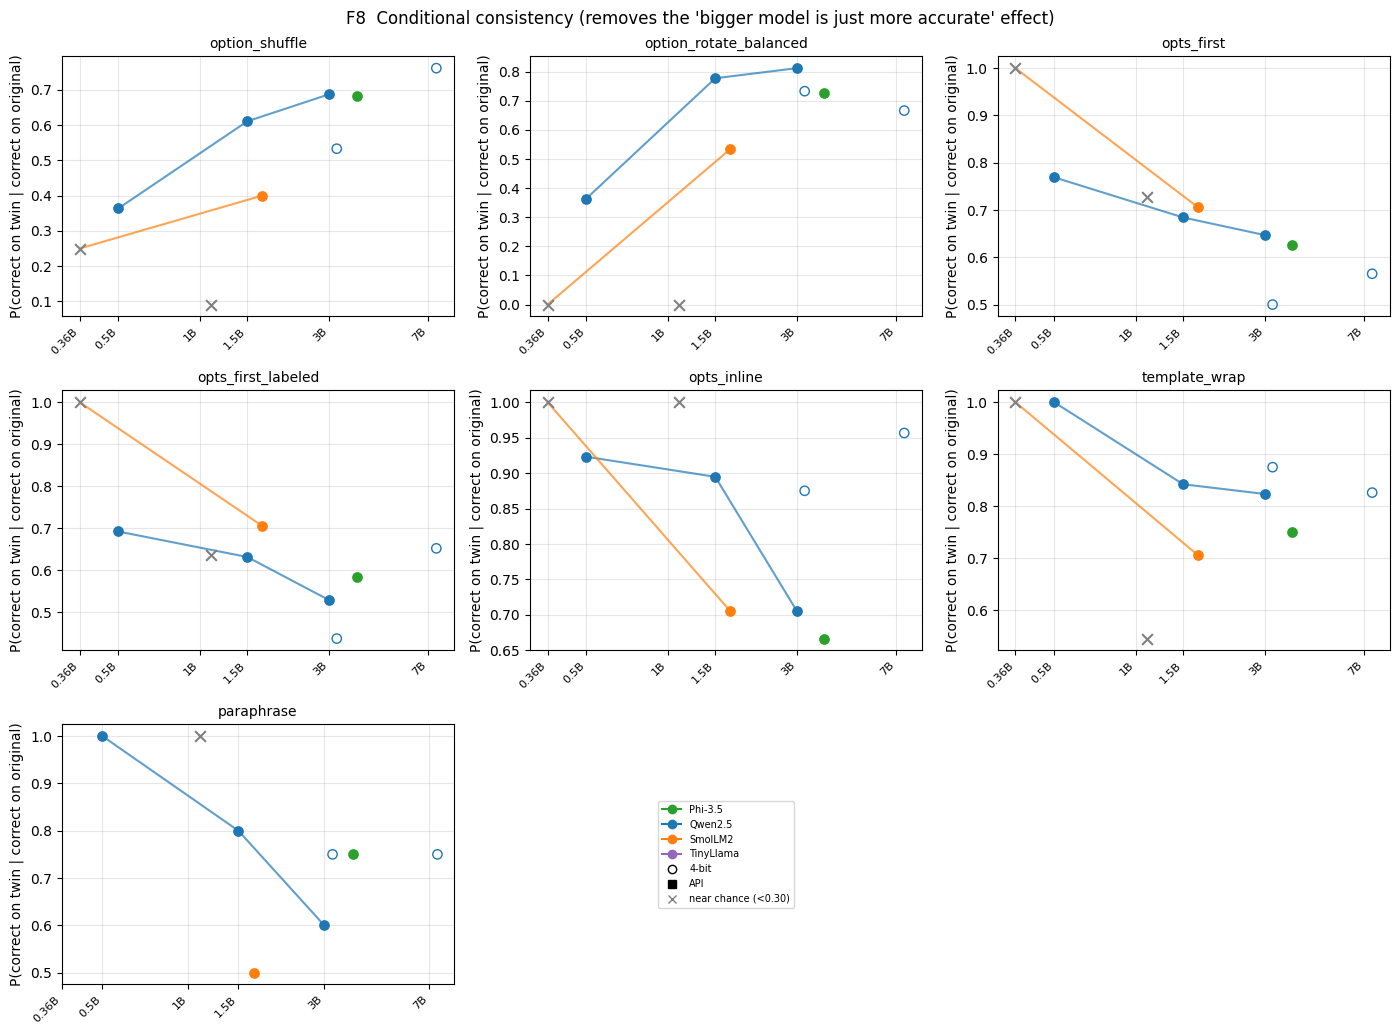

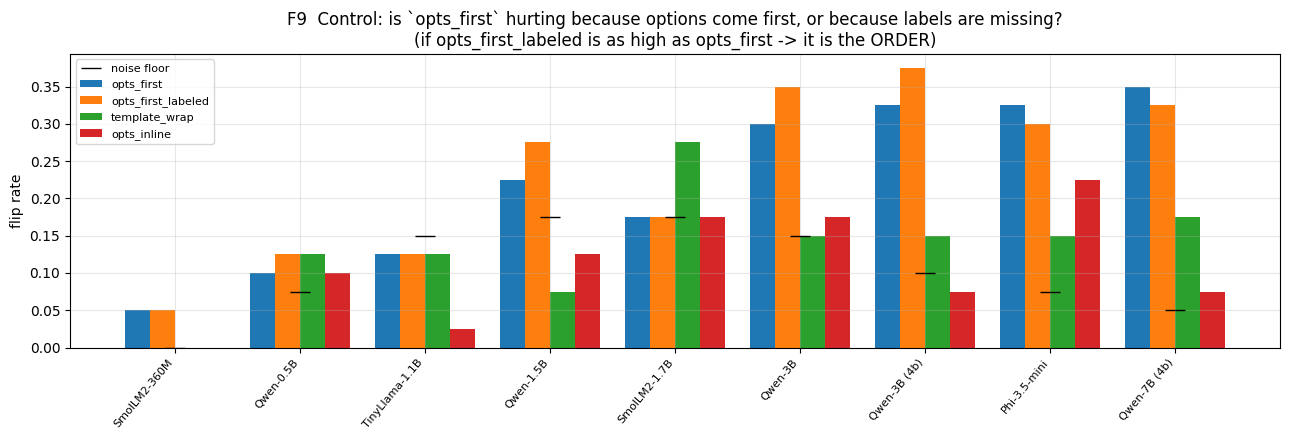

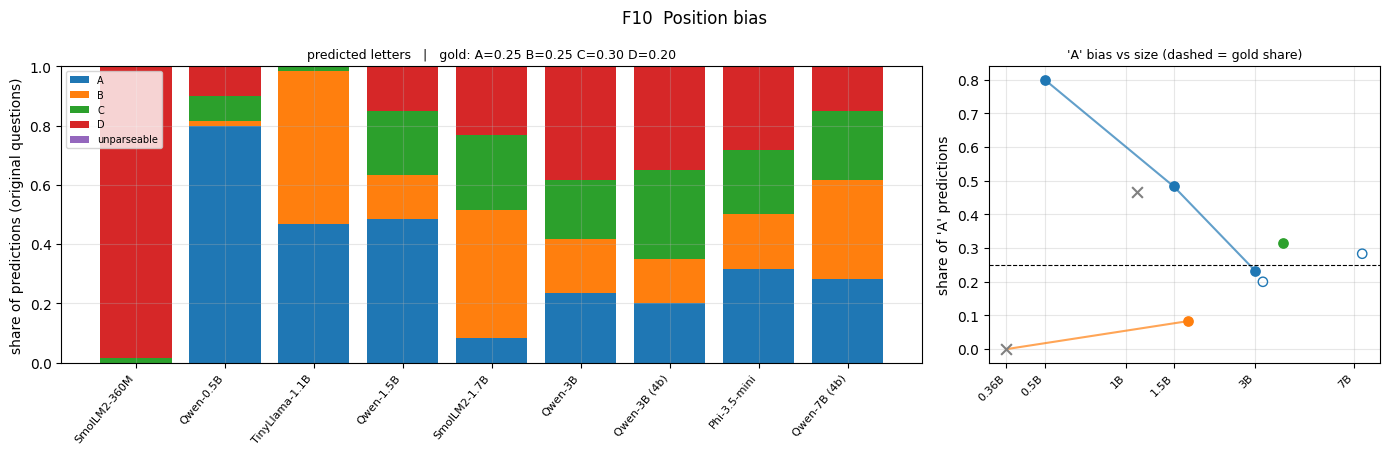

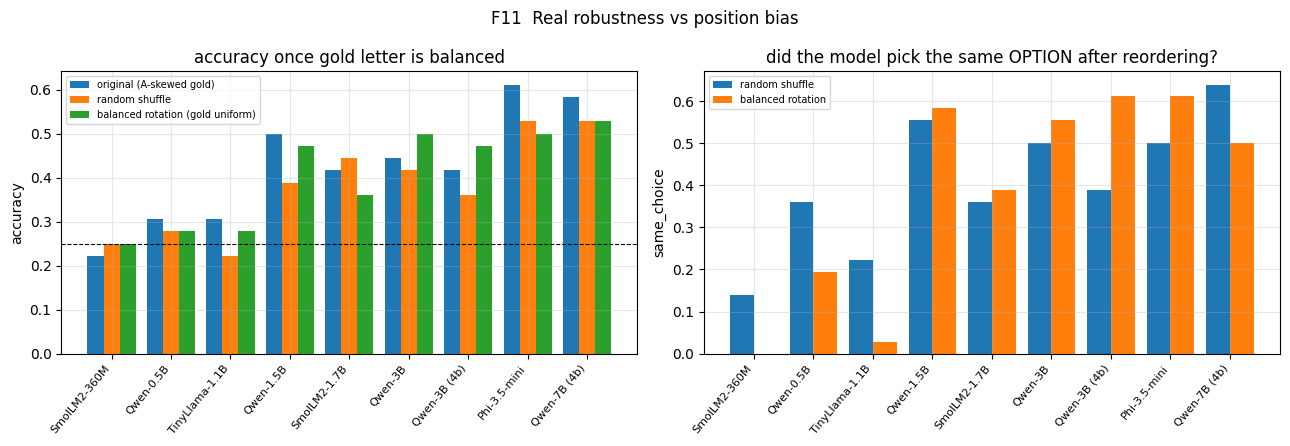

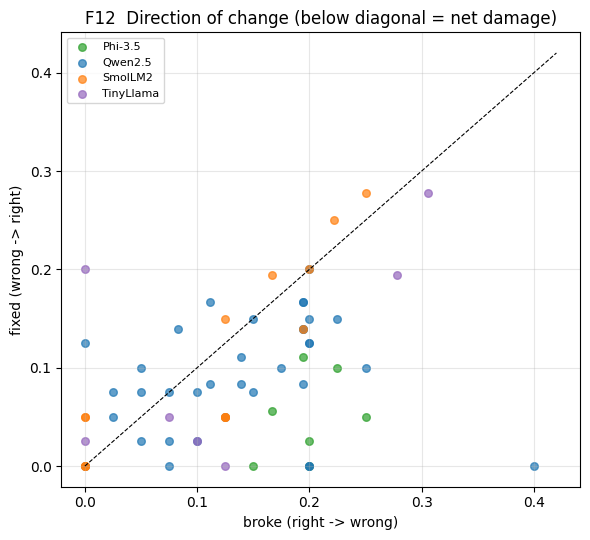

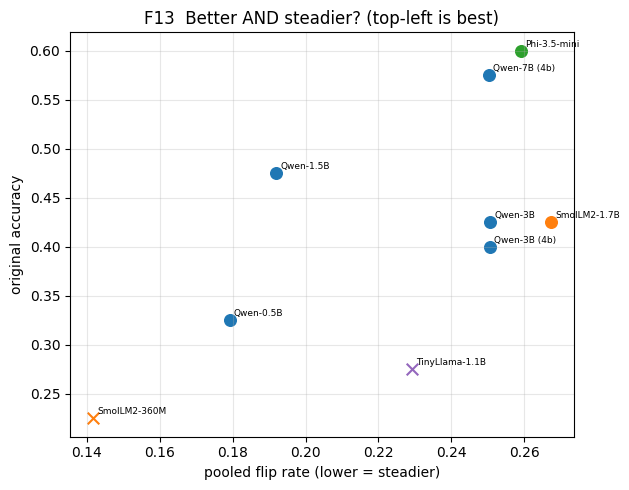

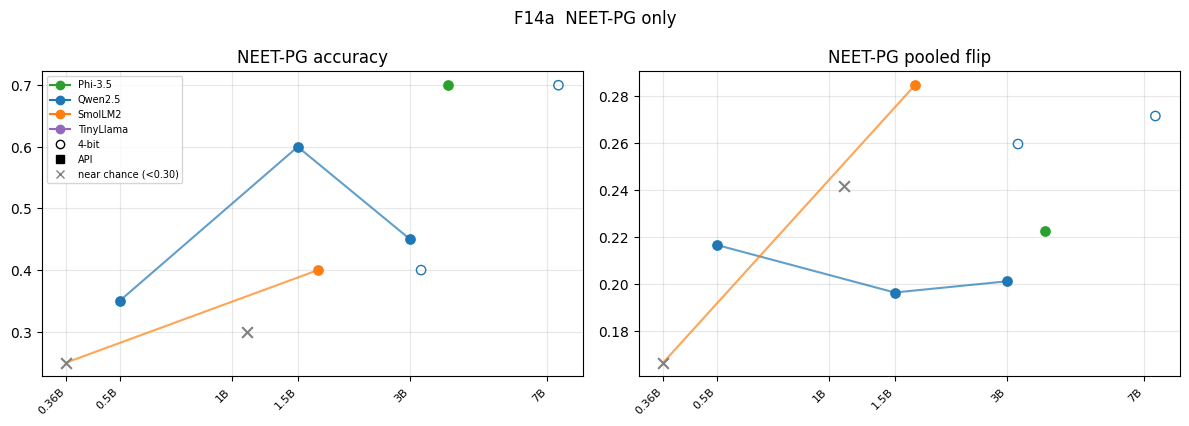

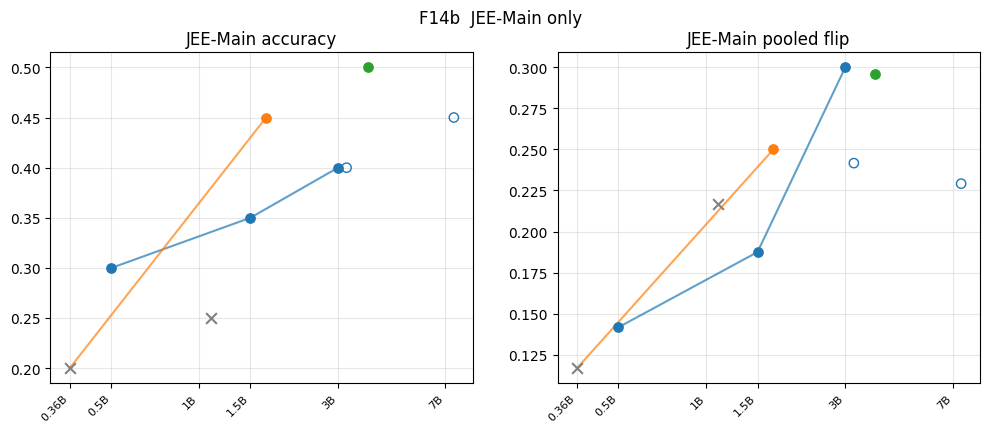


TREND (flip vs log size; rho<0 = bigger is steadier). p-values only reported with >=5 models.
 family           perturbation  n_models  spearman_rho   p  flip_smallest  flip_largest
Qwen2.5                    ALL         4         0.800 NaN          0.179         0.250
Qwen2.5         option_shuffle         4        -1.000 NaN          0.361         0.222
Qwen2.5 option_rotate_balanced         4        -0.200 NaN          0.361         0.333
Qwen2.5             opts_first         4         1.000 NaN          0.100         0.350
Qwen2.5     opts_first_labeled         4         0.800 NaN          0.125         0.325
Qwen2.5            opts_inline         4        -0.200 NaN          0.100         0.075
Qwen2.5          template_wrap         4         0.800 NaN          0.125         0.175
Qwen2.5             paraphrase         4         0.949 NaN          0.000         0.400

near-chance models (excluded from trends): ['SmolLM2-360M', 'TinyLlama-1.1B']
unparseable rate >1%: []


In [19]:
# ============================ ANALYSIS + FIGURES ============================
import glob, shutil
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

FIG = "figs_final"; os.makedirs(FIG, exist_ok=True)
rng = np.random.default_rng(0); B = 1000
MAIN_EXAMS = ["NEET-PG", "JEE-Main"]            # JEE-Adv (n=44 MCQ) is too small -> appendix only
GROUPS = {"position": ["option_shuffle", "option_rotate_balanced"],
          "layout": ["opts_first", "opts_first_labeled", "opts_inline", "template_wrap"],
          "semantic": ["paraphrase"], "noise": ["prefix_noise"], "exploratory": ["q_first"]}
POOL = GROUPS["position"] + GROUPS["layout"] + GROUPS["semantic"]     # pooled flip excludes noise control + q_first
NOISE = "prefix_noise"
FAMCOL = {"Qwen2.5": "tab:blue", "SmolLM2": "tab:orange", "Phi-3.5": "tab:green",
          "TinyLlama": "tab:purple", "Gemini": "tab:red"}
API_ORDER = []          # optional Gemini model(s) are appended automatically
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "figure.max_open_warning": 0})

# ------------------------------- load -------------------------------
df = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{PREFIX}_*.csv"))], ignore_index=True)
meta = df.drop_duplicates("model")[["model", "size_b", "family", "kind", "quant"]].reset_index(drop=True)
short = lambda m: (m.replace("-Instruct", "").replace("-instruct", "").replace("-Chat-v1.0", "")
                   .replace("Qwen2.5-", "Qwen-").replace("@4bit", " (4b)"))
meta["label"] = meta.model.map(short)
print("models:", meta.label.tolist())

# --------------------- paired original/twin table ---------------------
rows_ = []
for m, g in df.groupby("model"):
    o = g[g.perturbation == "original"].drop_duplicates("orig_id").set_index("orig_id")
    for p, t in g[g.perturbation != "original"].groupby("perturbation"):
        t = t.drop_duplicates("orig_id").set_index("orig_id")
        j = o.join(t, lsuffix="_o", rsuffix="_t", how="inner")
        rows_.append(pd.DataFrame({
            "model": m, "perturbation": p, "orig_id": j.index, "exam": j["exam_o"].values,
            "co": j["correct_o"].astype(bool).values, "ct": j["correct_t"].astype(bool).values,
            "same": (j["pred_orig_space_o"] == j["pred_orig_space_t"]).values}))
P = pd.concat(rows_, ignore_index=True)
P["flip"] = P.co != P.ct
P["broke"] = P.co & ~P.ct
P["fixed"] = ~P.co & P.ct
Pm = P[P.exam.isin(MAIN_EXAMS) & ~P.perturbation.isin(GROUPS["exploratory"])]   # q_first (n~50) -> appendix only
perts = [p for p in POOL + [NOISE] if p in set(Pm.perturbation)]
twin_perts = [p for p in perts if p != NOISE]


def boot(x):
    x = np.asarray(x, float)
    if len(x) == 0:
        return np.nan, np.nan, np.nan
    m = x[rng.integers(0, len(x), (B, len(x)))].mean(1)
    return x.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5)


# per-question flip series (cluster = question)
FQ = {(m, p): g.groupby("orig_id").flip.mean() for (m, p), g in Pm.groupby(["model", "perturbation"])}


def pooled_series(m):
    parts = [FQ[(m, p)] for p in POOL if (m, p) in FQ]
    return pd.concat(parts, axis=1).mean(axis=1) if parts else pd.Series(dtype=float)


# ---------------------- model-level summary M ----------------------
orig = df[(df.perturbation == "original") & df.exam.isin(MAIN_EXAMS)]
recs = []
for m in meta.model:
    om = orig[orig.model == m].drop_duplicates("orig_id")
    a, alo, ahi = boot(om.correct.astype(float))
    ps = pooled_series(m); f, flo, fhi = boot(ps)
    nz = FQ.get((m, NOISE), pd.Series(dtype=float))
    d = (ps - nz).dropna(); e, elo, ehi = boot(d)
    rec = dict(model=m, acc=a, acc_lo=alo, acc_hi=ahi, flip=f, flip_lo=flo, flip_hi=fhi,
               noise=nz.mean() if len(nz) else np.nan, excess=e, excess_lo=elo, excess_hi=ehi,
               n_q=len(om), unparseable=float((df[df.model == m].pred == "X").mean()))
    for ex in MAIN_EXAMS:
        rec[f"acc_{ex}"] = om[om.exam == ex].correct.mean()
        rec[f"flip_{ex}"] = ps[ps.index.isin(om[om.exam == ex].orig_id)].mean()
    recs.append(rec)
M = pd.DataFrame(recs).merge(meta, on="model")
M["near_chance"] = M.acc < 0.30
M.to_csv("model_summary.csv", index=False)

# --------------- per (model, perturbation) summary S + excess ---------------
recs = []
for (m, p), g in Pm.groupby(["model", "perturbation"]):
    f, flo, fhi = boot(FQ[(m, p)])
    rec = dict(model=m, perturbation=p, n=g.orig_id.nunique(), flip=f, flip_lo=flo, flip_hi=fhi,
               same=g.same.mean(), acc_o=g.groupby("orig_id").co.first().mean(), acc_t=g.ct.mean(),
               cond=g.ct[g.co].mean() if g.co.any() else np.nan, broke=g.broke.mean(), fixed=g.fixed.mean())
    if p != NOISE and (m, NOISE) in FQ:
        d = (FQ[(m, p)] - FQ[(m, NOISE)]).dropna(); e, elo, ehi = boot(d)
        rec.update(excess=e, excess_lo=elo, excess_hi=ehi, sig=bool(elo > 0 or ehi < 0))
    recs.append(rec)
S = pd.DataFrame(recs).merge(meta, on="model")
S.to_csv("summary.csv", index=False)
S[S.perturbation != NOISE][["label", "perturbation", "n", "flip", "excess", "excess_lo", "excess_hi", "sig"]] \
    .round(3).to_csv("excess_table.csv", index=False)

# -------- appendix (excluded from main claims): JEE-Adv and q_first --------
Pa = P[(P.exam == "JEE-Adv") | (P.perturbation == "q_first")]
App = Pa.groupby(["model", "exam", "perturbation"]).agg(n=("flip", "size"), flip=("flip", "mean"),
                                                       acc_o=("co", "mean"), acc_t=("ct", "mean")).round(3).reset_index()
App.to_csv("appendix_excluded_results.csv", index=False)


# ------------------------------ plotting helpers ------------------------------
def make_xmap(M):
    xm = {}
    for _, r in M[M.kind == "local"].iterrows():
        xm[r.model] = r.size_b * (1.07 if r.quant else 1.0)
    base_x = max([v for v in xm.values()] + [1]) * 2.6
    apis = [m for m in API_ORDER if m in set(M.model)] + sorted(set(M[M.kind == "api"].model) - set(API_ORDER))
    for k, m in enumerate(apis):
        xm[m] = base_x * 1.7 ** k
    return xm


XM = make_xmap(M)
order = sorted(M.model, key=lambda m: XM[m])


def style_axis(ax):
    ticks = [t for t in [0.36, 0.5, 1, 1.5, 3, 7] if min(XM.values()) / 1.2 <= t <= 8]
    apis = [m for m in XM if M.set_index("model").loc[m, "kind"] == "api"]
    ax.set_xscale("log")
    ax.set_xticks(ticks + [XM[a] for a in apis])
    ax.set_xticklabels([f"{t:g}B" for t in ticks] + [short(a) for a in apis],
                       rotation=45, ha="right", fontsize=8)
    ax.minorticks_off()


def family_legend(ax, fams=None, loc="best"):
    from matplotlib.lines import Line2D
    fams = fams or sorted(M.family.unique())
    h = [Line2D([0], [0], color=FAMCOL.get(f, "gray"), marker="o", label=f) for f in fams]
    h += [Line2D([0], [0], color="k", marker="o", mfc="none", ls="", label="4-bit"),
          Line2D([0], [0], color="k", marker="s", ls="", label="API"),
          Line2D([0], [0], color="gray", marker="x", ls="", label="near chance (<0.30)")]
    ax.legend(handles=h, fontsize=7, loc=loc)


def vs_size(ax, T, y, lo=None, hi=None):
    """T has columns model + y (+ lo/hi). one coloured line per local family, markers per model"""
    T = T.assign(x=T.model.map(XM)).merge(M[["model", "family", "kind", "quant", "near_chance"]], on="model",
                                         suffixes=("", "_m"))
    for fam, g in T.groupby("family"):
        col = FAMCOL.get(fam, "gray")
        loc = g[(g.kind == "local") & ~g.quant].sort_values("x")
        if len(loc) > 1:
            ax.plot(loc.x, loc[y], "-", color=col, alpha=.7)
        for _, r in g.iterrows():
            mk = "s" if r.kind == "api" else "o"
            if r.near_chance:
                ax.scatter(r.x, r[y], marker="x", color="gray", s=60, zorder=4)
            else:
                ax.scatter(r.x, r[y], marker=mk, s=45, zorder=3,
                           facecolors="none" if r.quant else col, edgecolors=col)
            if lo and not np.isnan(r[lo]):
                ax.errorbar(r.x, r[y], yerr=[[r[y] - r[lo]], [r[hi] - r[y]]], fmt="none", ecolor=col, alpha=.5, capsize=2)
    style_axis(ax)


def done(fig, name):
    fig.tight_layout(); fig.savefig(f"{FIG}/{name}.png", dpi=150); plt.show(); plt.close(fig)


def heat(Mx, title, name, fmt="{:.2f}", cmap="viridis", stars=None):
    fig, ax = plt.subplots(figsize=(1.05 * Mx.shape[1] + 3, 0.5 * Mx.shape[0] + 2))
    im = ax.imshow(Mx.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(Mx.shape[1])); ax.set_xticklabels(Mx.columns, rotation=40, ha="right")
    ax.set_yticks(range(Mx.shape[0])); ax.set_yticklabels(Mx.index)
    for i in range(Mx.shape[0]):
        for j in range(Mx.shape[1]):
            v = Mx.values[i, j]
            if not np.isnan(v):
                s = fmt.format(v) + ("*" if stars is not None and stars.values[i, j] else "")
                ax.text(j, i, s, ha="center", va="center", color="w", fontsize=8)
    ax.grid(False); ax.set_title(title); fig.colorbar(im, ax=ax)
    done(fig, name)


Mi = M.set_index("model")
# ------------------------------ F1 headline bars ------------------------------
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
cols = [FAMCOL.get(Mi.loc[m, "family"], "gray") for m in order]
for ax, (y, lo, hi, ttl) in zip(axs, [("acc", "acc_lo", "acc_hi", "Original accuracy (NEET-PG + JEE-Main)"),
                                     ("flip", "flip_lo", "flip_hi", "Pooled flip rate over perturbations (lower = steadier)")]):
    v = np.array([Mi.loc[m, y] for m in order])
    ax.bar(range(len(order)), v, color=cols, alpha=.85,
           yerr=[v - np.array([Mi.loc[m, lo] for m in order]), np.array([Mi.loc[m, hi] for m in order]) - v], capsize=2)
    if y == "acc":
        ax.axhline(.25, color="k", ls="--", lw=.8)
    else:
        ax.plot(range(len(order)), [Mi.loc[m, "noise"] for m in order], "k_", ms=18, label="noise floor (prefix_noise)")
        ax.legend(fontsize=8)
    ax.set_xticks(range(len(order))); ax.set_xticklabels([Mi.loc[m, "label"] for m in order], rotation=50, ha="right", fontsize=8)
    ax.set_title(ttl, fontsize=10)
fig.suptitle("F1  Headline: all models (bars sorted by size; API models at the right)")
done(fig, "F01_headline_accuracy_and_flip")

# ------------------------------ F2 accuracy vs size ------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))
vs_size(ax, M[["model", "acc", "acc_lo", "acc_hi"]], "acc", "acc_lo", "acc_hi")
ax.axhline(.25, color="k", ls="--", lw=.8); ax.set_ylabel("original accuracy"); family_legend(ax)
ax.set_title("F2  Accuracy vs model size (chance = 0.25)")
done(fig, "F02_accuracy_vs_size")

# ------------------------------ F3 pooled flip vs size + noise floor ------------------------------
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
vs_size(axs[0], M[["model", "flip", "flip_lo", "flip_hi"]], "flip", "flip_lo", "flip_hi")
vs_size(axs[0], M[["model", "noise"]].assign(noise_lo=np.nan, noise_hi=np.nan), "noise")
axs[0].set_ylabel("pooled flip rate"); axs[0].set_title("pooled flip (dots with CI) vs noise floor (same markers, lower)")
vs_size(axs[1], M[["model", "excess", "excess_lo", "excess_hi"]], "excess", "excess_lo", "excess_hi")
axs[1].axhline(0, color="k", lw=.8); axs[1].set_ylabel("flip - noise floor"); family_legend(axs[1])
axs[1].set_title("excess over noise floor (paired per question)")
fig.suptitle("F3  Does scale buy robustness?")
done(fig, "F03_pooled_flip_vs_size")

# ------------------------------ F4 excess per perturbation ------------------------------
n = len(twin_perts); cols_ = 3; rws = int(np.ceil(n / cols_))
fig, axs = plt.subplots(rws, cols_, figsize=(4.7 * cols_, 3.5 * rws), squeeze=False)
for ax, p in zip(axs.ravel(), twin_perts):
    sub = S[S.perturbation == p][["model", "excess", "excess_lo", "excess_hi"]].dropna()
    vs_size(ax, sub, "excess", "excess_lo", "excess_hi"); ax.axhline(0, color="k", lw=.8)
    ax.set_title(p, fontsize=10); ax.set_ylabel("flip - noise floor")
family_legend(axs.ravel()[n] if n < rws * cols_ else axs.ravel()[0], loc="center")
for ax in axs.ravel()[n:]:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle("F4  Excess flip over noise floor, per perturbation (95% CI, paired)")
done(fig, "F04_excess_per_perturbation")

# ------------------------------ F5-F7 heatmaps ------------------------------
lab = lambda Mx: Mx.rename(index=Mi.label.to_dict())
Hf = S.pivot(index="model", columns="perturbation", values="flip").reindex(order)[perts]
heat(lab(Hf), "F5  Flip rate (lower = more robust; prefix_noise = noise floor)", "F05_heatmap_flip", cmap="magma")
He = S[S.perturbation != NOISE].pivot(index="model", columns="perturbation", values="excess").reindex(order)[twin_perts]
Hs = S[S.perturbation != NOISE].pivot(index="model", columns="perturbation", values="sig").reindex(order)[twin_perts].fillna(False).astype(bool)
heat(lab(He), "F6  Excess flip over noise floor (* = 95% CI excludes 0)", "F06_heatmap_excess", cmap="coolwarm", stars=lab(Hs))
Hc = S.pivot(index="model", columns="perturbation", values="same").reindex(order)[perts]
heat(lab(Hc), "F7  same_choice (higher = more consistent)", "F07_heatmap_same_choice")

# ------------------------------ F8 conditional consistency ------------------------------
fig, axs = plt.subplots(rws, cols_, figsize=(4.7 * cols_, 3.5 * rws), squeeze=False)
for ax, p in zip(axs.ravel(), twin_perts):
    vs_size(ax, S[S.perturbation == p][["model", "cond"]].dropna(), "cond"); ax.set_title(p, fontsize=10)
    ax.set_ylabel("P(correct on twin | correct on original)")
family_legend(axs.ravel()[n] if n < rws * cols_ else axs.ravel()[0], loc="center")
for ax in axs.ravel()[n:]:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle("F8  Conditional consistency (removes the 'bigger model is just more accurate' effect)")
done(fig, "F08_conditional_consistency")

# ------------------------------ F9 layout-order control ------------------------------
lay = [p for p in ["opts_first", "opts_first_labeled", "template_wrap", "opts_inline"] if p in twin_perts]
fig, ax = plt.subplots(figsize=(1.0 * len(order) + 4, 4.5)); w = .8 / max(len(lay), 1)
for k, p in enumerate(lay):
    v = [S[(S.model == m) & (S.perturbation == p)].flip.mean() for m in order]
    ax.bar(np.arange(len(order)) + k * w, v, w, label=p)
ax.plot(np.arange(len(order)) + .4 - w / 2, [Mi.loc[m, "noise"] for m in order], "k_", ms=14, label="noise floor")
ax.set_xticks(np.arange(len(order)) + .4 - w / 2); ax.set_xticklabels([Mi.loc[m, "label"] for m in order], rotation=50, ha="right", fontsize=8)
ax.set_ylabel("flip rate"); ax.legend(fontsize=8)
ax.set_title("F9  Control: is `opts_first` hurting because options come first, or because labels are missing?\n"
             "(if opts_first_labeled is as high as opts_first -> it is the ORDER)")
done(fig, "F09_layout_control")

# ------------------------------ F10 position bias ------------------------------
o_all = df[df.perturbation == "original"]
D = {m: o_all[o_all.model == m].pred.value_counts(normalize=True).reindex(list("ABCDX")).fillna(0) for m in order}
gold = o_all.drop_duplicates("orig_id").answer.value_counts(normalize=True).reindex(list("ABCD")).fillna(0)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
bottom = np.zeros(len(order))
for l in "ABCDX":
    v = np.array([D[m][l] for m in order]); axs[0].bar(range(len(order)), v, bottom=bottom, label=l if l != "X" else "unparseable"); bottom += v
axs[0].set_xticks(range(len(order))); axs[0].set_xticklabels([Mi.loc[m, "label"] for m in order], rotation=50, ha="right", fontsize=8)
axs[0].legend(fontsize=7); axs[0].set_ylabel("share of predictions (original questions)")
axs[0].set_title("predicted letters   |   gold: " + " ".join(f"{l}={gold[l]:.2f}" for l in "ABCD"), fontsize=9)
tA = pd.DataFrame({"model": order, "A_share": [D[m]["A"] for m in order]})
vs_size(axs[1], tA, "A_share"); axs[1].axhline(gold["A"], color="k", ls="--", lw=.8)
axs[1].set_ylabel("share of 'A' predictions"); axs[1].set_title("'A' bias vs size (dashed = gold share)", fontsize=9)
fig.suptitle("F10  Position bias"); done(fig, "F10_position_bias")

# ------------------------------ F11 balanced rotation ------------------------------
if "option_rotate_balanced" in twin_perts:
    R = S[S.perturbation == "option_rotate_balanced"].set_index("model").reindex(order)
    Rr = S[S.perturbation == "option_shuffle"].set_index("model").reindex(order)
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.5)); x = np.arange(len(order))
    axs[0].bar(x - .27, R.acc_o, .27, label="original (A-skewed gold)"); axs[0].bar(x, Rr.acc_t, .27, label="random shuffle")
    axs[0].bar(x + .27, R.acc_t, .27, label="balanced rotation (gold uniform)"); axs[0].axhline(.25, color="k", ls="--", lw=.8)
    axs[0].set_ylabel("accuracy"); axs[0].legend(fontsize=7); axs[0].set_title("accuracy once gold letter is balanced")
    axs[1].bar(x - .2, Rr.same, .4, label="random shuffle"); axs[1].bar(x + .2, R.same, .4, label="balanced rotation")
    axs[1].set_ylabel("same_choice"); axs[1].legend(fontsize=7); axs[1].set_title("did the model pick the same OPTION after reordering?")
    for ax in axs:
        ax.set_xticks(x); ax.set_xticklabels([Mi.loc[m, "label"] for m in order], rotation=50, ha="right", fontsize=8)
    fig.suptitle("F11  Real robustness vs position bias"); done(fig, "F11_balanced_rotation")

# ------------------------------ F12 broke vs fixed ------------------------------
fig, ax = plt.subplots(figsize=(6, 5.5))
for fam, g in S[S.perturbation != NOISE].groupby("family"):
    ax.scatter(g.broke, g.fixed, color=FAMCOL.get(fam, "gray"), alpha=.7, label=fam, s=30)
mx = max(S.broke.max(), S.fixed.max()) * 1.05; ax.plot([0, mx], [0, mx], "k--", lw=.8)
ax.set_xlabel("broke (right -> wrong)"); ax.set_ylabel("fixed (wrong -> right)"); ax.legend(fontsize=8)
ax.set_title("F12  Direction of change (below diagonal = net damage)"); done(fig, "F12_broke_vs_fixed")

# ------------------------------ F13 accuracy vs flip ------------------------------
fig, ax = plt.subplots(figsize=(6.4, 5))
for _, r in M.iterrows():
    ax.scatter(r.flip, r.acc, s=70, color=FAMCOL.get(r.family, "gray"), marker="s" if r.kind == "api" else ("x" if r.near_chance else "o"))
    ax.annotate(r.label, (r.flip, r.acc), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("pooled flip rate (lower = steadier)"); ax.set_ylabel("original accuracy")
ax.set_title("F13  Better AND steadier? (top-left is best)"); done(fig, "F13_accuracy_vs_flip")

# ------------------------------ F14 per exam ------------------------------
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
vs_size(axs[0], M.assign(v=M["acc_NEET-PG"])[["model", "v"]], "v"); vs_size(axs[1], M.assign(v=M["flip_NEET-PG"])[["model", "v"]], "v")
for ax, ttl in zip(axs, ["NEET-PG accuracy", "NEET-PG pooled flip"]):
    ax.set_title(ttl)
fig2, axs2 = plt.subplots(1, 2, figsize=(12, 4.3))
vs_size(axs2[0], M.assign(v=M["acc_JEE-Main"])[["model", "v"]], "v"); vs_size(axs2[1], M.assign(v=M["flip_JEE-Main"])[["model", "v"]], "v")
for ax, ttl in zip(axs2, ["JEE-Main accuracy", "JEE-Main pooled flip"]):
    ax.set_title(ttl)
family_legend(axs[0]); fig.suptitle("F14a  NEET-PG only"); fig2.suptitle("F14b  JEE-Main only")
done(fig, "F14a_neetpg_only"); done(fig2, "F14b_jeemain_only")

# ------------------------------ trend table (within-family, near-chance excluded) ------------------------------
trend = []
for fam in sorted(M.family.unique()):
    g0 = M[(M.family == fam) & (M.kind == "local")]
    g0 = g0[~(g0.quant & g0.size_b.isin(g0[~g0.quant].size_b)) & ~g0.near_chance].sort_values("size_b")   # drop 3B@4bit control
    if len(g0) < 3:
        continue
    for p in ["ALL"] + twin_perts:
        if p == "ALL":
            y = g0.flip.values
        else:
            y = np.array([S[(S.model == m) & (S.perturbation == p)].flip.mean() for m in g0.model])
        rho, pv = spearmanr(np.log(g0.size_b), y)
        trend.append(dict(family=fam, perturbation=p, n_models=len(g0), spearman_rho=rho,
                          p=pv if len(g0) >= 5 else np.nan, flip_smallest=y[0], flip_largest=y[-1]))
T = pd.DataFrame(trend).round(3); T.to_csv("trend_table.csv", index=False)
print("\nTREND (flip vs log size; rho<0 = bigger is steadier). p-values only reported with >=5 models.")
print(T.to_string(index=False) if len(T) else "(fewer than 3 usable models per family)")
print("\nnear-chance models (excluded from trends):", M[M.near_chance].label.tolist())
print("unparseable rate >1%:", M[M.unparseable > .01][["label", "unparseable"]].round(3).values.tolist())


## 10 · Digest + zip  (paste `RESULTS_DIGEST.txt` into the chat to get the PPT)

In [20]:
# ======================= DIGEST (paste this into the chat / use for the PPT) =======================
import io, json as _json
buf = io.StringIO()
pr = lambda *a: print(*a, file=buf)
pr("PERTURBBENCH RESULTS DIGEST  | exams in main claims:", MAIN_EXAMS, "| questions per model:", int(M.n_q.max()))
pr("\n== MODEL SUMMARY (acc, pooled flip, noise floor, excess over noise)")
pr(M.sort_values("size_b")[["label", "family", "size_b", "acc", "acc_NEET-PG", "acc_JEE-Main", "flip", "noise", "excess",
                           "excess_lo", "excess_hi", "near_chance", "unparseable"]].round(3).to_string(index=False))
pr("\n== EXCESS FLIP OVER NOISE PER PERTURBATION (* = CI excludes 0)")
tmp = S[S.perturbation != NOISE].copy()
tmp["cell"] = tmp.excess.round(3).astype(str) + tmp.sig.map({True: "*", False: ""}).fillna("")
pr(tmp.pivot(index="label", columns="perturbation", values="cell").to_string())
pr("\n== SAME_CHOICE")
pr(S.pivot(index="label", columns="perturbation", values="same").round(2).to_string())
pr("\n== TREND (within family)"); pr(T.to_string(index=False) if len(T) else "n/a")
cal = f"{PREFIX}_calibration.json"
pr("\n== CALIBRATION (logit scoring vs generation+parsing, same model)")
pr(open(cal).read() if os.path.exists(cal) else "n/a")
pr("\n== PARAPHRASER USED:", open("paraphraser_used.txt").read().strip() if os.path.exists("paraphraser_used.txt") else "n/a")
pr("(Gemini rows, if any, cover only a small question subset -> wide CIs; not comparable to the full-set local rows)")
pr("\n== A-share of predictions (gold A =", round(float(gold["A"]), 2), ")")
pr(pd.Series({Mi.loc[m, "label"]: round(D[m]["A"], 2) for m in order}).to_string())
pr("\n== EXCLUDED FROM MAIN CLAIMS: JEE-Adv (n<=44 MCQ), q_first (n=58), near-chance models -> see appendix_excluded_results.csv")
digest = buf.getvalue(); open("RESULTS_DIGEST.txt", "w").write(digest); print(digest)

# --------- zip everything + download ---------
shutil.make_archive("results_final", "zip", ".", FIG)
for f in ["summary.csv", "model_summary.csv", "excess_table.csv", "trend_table.csv", "appendix_excluded_results.csv", "RESULTS_DIGEST.txt"]:
    shutil.copy(f, FIG)
shutil.make_archive("results_final", "zip", ".", FIG)
try:
    from google.colab import files
    files.download("results_final.zip")
except Exception as e:
    print("download skipped:", e)
print("\nSaved in Drive:", os.getcwd(), "->", FIG, "/ results_final.zip")


PERTURBBENCH RESULTS DIGEST  | exams in main claims: ['NEET-PG', 'JEE-Main'] | questions per model: 40

== MODEL SUMMARY (acc, pooled flip, noise floor, excess over noise)
         label    family  size_b   acc  acc_NEET-PG  acc_JEE-Main  flip  noise  excess  excess_lo  excess_hi  near_chance  unparseable
  SmolLM2-360M   SmolLM2    0.36 0.225         0.25          0.20 0.142  0.000   0.142      0.099      0.189         True          0.0
     Qwen-0.5B   Qwen2.5    0.50 0.325         0.35          0.30 0.179  0.075   0.104     -0.000      0.182        False          0.0
TinyLlama-1.1B TinyLlama    1.10 0.275         0.30          0.25 0.229  0.150   0.079     -0.048      0.189         True          0.0
     Qwen-1.5B   Qwen2.5    1.50 0.475         0.60          0.35 0.192  0.175   0.017     -0.105      0.135        False          0.0
  SmolLM2-1.7B   SmolLM2    1.70 0.425         0.40          0.45 0.267  0.175   0.092     -0.023      0.210        False          0.0
  Qwen-3B (4b)   Q

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved in Drive: /content/drive/MyDrive/PerturbBench -> figs_final / results_final.zip
